# Piror ro Aug 13

* do the numerical/analytical comparasion approaching where $a_N\simeq a_{Q^*}$
* do 2 by 2 plot where horizontal axis is $\Delta n/n_0$, and no need to shoot $n_{crit}$ up to $5n_0$
* get the approximate $\Delta n_{max}$ or $\Delta P_{max}$ where $a_N\simeq a_{Q^*}$

In [138]:
import numpy as np
import time
import matplotlib.pyplot as plt
from scipy.integrate import quad
from scipy.optimize import fsolve, approx_fprime, root_scalar, root, least_squares
from numdifftools import Gradient, Derivative
import RMFsolver.constants as const
import RMFsolver.RMFparameter as para
from RMFsolver.Solver import RMFsolve_mu, RMFpressureSYM, RMFpressurePNM, pressure_RMF
from RMFsolver.phase_velocity import P_f, vNtoQ_Pc, vNtoQ_B, vNtoQ_nc, PQM, PQM_em, Get_Delta_n_max, _find_muB_muK_star

def PNM(mu_B, Temp, param=para.paraQMCRMF3, ):
    pre = RMFpressurePNM(
        input_num = mu_B,
        input_type = "muB", 
        Trmf = Temp, 
        para = param, 
        sigma_init = 30, 
        w0_init = 20, 
        r03_init = -3, 
        mub_init = 990,
        verb = False
        )
    return float(pre.item())

def PNM_n(nB, Temp):
    pre = RMFpressurePNM(
        input_num = nB,
        input_type = "nB", 
        Trmf = Temp, 
        para = param, 
        sigma_init = 30, 
        w0_init = 20, 
        r03_init = -3, 
        mub_init = 990,
        verb = False
        )
    return float(pre.item())

n0 = 0.16 * const.MeV_fm**3

In [38]:
T = 15
n_crit = 2.5 * n0
Deln = 0.005 * n_crit
m_s = 0
param = para.paraQMCRMF3
NM_type = "PNM"
method = "numerical"

# solve for bag constant
P_crit = PNM_n(n_crit, T)
P_diff = lambda x: PNM(x, T) - P_crit
muB_crit = fsolve(P_diff, 1050)[0]
PQM_solve_for_B = lambda x: PQM(muB_crit, 0, x, T, m_s) - P_crit
B_SQM = fsolve(PQM_solve_for_B, 180)[0]

# solve for points Q and N at beta eq.
DelP = PNM_n(n_crit + Deln, T) - P_crit
PNM_minus_PShift = lambda x: PNM(x,T) - P_crit - DelP
muB_N = fsolve(PNM_minus_PShift, 1050)[0]

PQM_minus_Pshift = lambda x: PQM(x, 0, B_SQM, T, m_s) - P_crit - DelP
muB_Q = fsolve(PQM_minus_Pshift, 1050)[0]

# calculating aQstar
if method == "numerical":
    epsilon = np.sqrt(np.finfo(float).eps)
    muB_star, muK_star = _find_muB_muK_star(PQM, P_crit + DelP, muB_N, B_SQM, T, m_s)
    PQM_wrap = lambda Mu: PQM(Mu[0], Mu[1], B_SQM, T, m_s)
    grad_Qstar = approx_fprime(np.array([muB_star, muK_star]), PQM_wrap, epsilon)
    nB_Qstar = grad_Qstar[0]
    nK_Qstar = grad_Qstar[1]
    grad_Q = approx_fprime(np.array([muB_Q, 0]), PQM_wrap, epsilon)
    nB_Q = grad_Q[0]
    nK_Q = grad_Q[1]
    aQstar = (nK_Qstar - nK_Q)/nB_Q  

elif method == "analytical":
    PQM_muB = lambda Mu: PQM(Mu, 0, B_SQM, T, m_s)
    PQM_muK = lambda Mu: PQM(muB_Q, Mu, B_SQM, T, m_s)
    ddPQM_ddmuK = Derivative(PQM_muK, n=2)
    dPQM_dmuK = Derivative(PQM_muK, n=1)
    dPQM_dmuB = Derivative(PQM_muB, n=1)
    chiK_Q = ddPQM_ddmuK(0)
    nB_Q = dPQM_dmuB(muB_Q)
    nK_Q = dPQM_dmuK(0)
    aQstar = np.sqrt(2*(muB_N - muB_Q)*chiK_Q / nB_Q)
    muK_star = np.sqrt(2 * nB_Q * (muB_N - muB_Q) / chiK_Q)
    PQM_solve_for_muBstar = lambda x: PQM(x, muK_star, B_SQM, T, m_s) - P_crit
    muB_star = fsolve(PQM_solve_for_muBstar, muB_Q)[0]

else:
    raise RuntimeError(f"Input method unknown")

# calculating aN
PNM_wrap = lambda x: PNM(x, T)
dPNM_dmuB = Derivative(PNM_wrap, n=1)
nB_N = dPNM_dmuB(muB_N)
aN = (nB_N - nK_Q) / nB_Q   

muQ = muB_star/3

alpha_s = 0.3
g_s = np.sqrt(4 * np.pi * alpha_s)

# Compute intermediate quantities
etaQ = (9 * np.pi**2 * T**2) / muQ**2
tauQ = 1.98e12 * ((300 / muQ)**5)
qD = np.sqrt(3 * g_s**2 * muQ**2 / (2 * np.pi**2))
h = 1.81317

part1 = h*T**(5/3)/qD**(2/3)
part2 = np.pi**3 * T**2 / (12*qD)

DQ = 1/( 24*alpha_s**2/np.pi * ( part1 + part2 ) )
# DQ = (np.pi / (24 * (0.3)**2 * 1.81 * T**(5/3))) * ((6 * 0.3 / np.pi * muQ**2)**(1/3))

# Compute v_N->Q
vNQ = np.sqrt((DQ / tauQ) * ((aQstar**4 + 2 * etaQ * aQstar**2) / (2 * aN * (aN - aQstar)))) * 3e8

print(" \[Mu]Q    =", muQ, ';\n', "aQstar    =", aQstar, ';\n', "aN        =", aN, ';\n', "vNQ       =", vNQ, "/(3*^8);")

<>:80: SyntaxWarning: invalid escape sequence '\['
<>:80: SyntaxWarning: invalid escape sequence '\['
/var/folders/zx/mchmm24s5sj4l19_jxvlkj380000gn/T/ipykernel_5695/417707273.py:80: SyntaxWarning: invalid escape sequence '\['
  print(" \[Mu]Q    =", muQ, ';\n', "aQstar    =", aQstar, ';\n', "aN        =", aN, ';\n', "vNQ       =", vNQ, "/(3*^8);")


 \[Mu]Q    = 371.0831879826994 ;
 aQstar    = 0.07673185434302902 ;
 aN        = 0.5859546030304538 ;
 vNQ       = 9.71514528974231 /(3*^8);


In [18]:
P_crit/1e8, DelP/1e8, muB_Q, muB_N, muK_star, B_SQM

(3.542592408984268,
 0.5724109008236152,
 np.float64(1123.6809302261904),
 np.float64(1131.113373445982),
 np.float64(61.45373578299545),
 np.float64(183.41929268544348))

In [10]:
(0.98632 - 1) * 100, 398*3

(-1.3680000000000025, 1194)

In [5]:
vNtoQ_nc(
    T = 20,
    n_crit = 5*n0,
    Deln = 0.015*5*n0,
    m_s = 0,
    param = para.paraQMCRMF3,
    NM_type = "PNM",
    method = "numerical"
)

(np.float64(120.16414964172438), np.float64(241.6566500172263))

### 3rd, get $\Delta n_{max}$

In [2]:
import numpy as np
import time
import matplotlib.pyplot as plt
from scipy.integrate import quad
from scipy.optimize import fsolve, approx_fprime, root_scalar, root, least_squares
from numdifftools import Gradient, Derivative
import RMFsolver.constants as const
import RMFsolver.RMFparameter as para
from RMFsolver.Solver import RMFsolve_mu, RMFpressureSYM, RMFpressurePNM, pressure_RMF
from RMFsolver.phase_velocity import P_f, vNtoQ_Pc, vNtoQ_B, vNtoQ_nc, PQM, PQM_em, Get_Delta_n_max#, _old_Get_Delta_n_max

n0 = 0.16 * const.MeV_fm**3

In [4]:
start = time.time()
Deln_max = Get_Delta_n_max(
    T = 75, 
    n_crit = 4.5*n0, 
    m_s = 0, 
    param=para.paraQMCRMF3, 
    NM_type = 'PNM',
    method = 'numerical',
    tol = 5e-3
)
end = time.time()

Deln_max / n0, end - start

(0.7230552767516486, 49.91573095321655)

In [5]:
start = time.time()
Deln_max = _old_Get_Delta_n_max(
    T = 50, 
    n_crit = 3*n0, 
    m_s = 0, 
    param=para.paraQMCRMF3, 
    NM_type = 'PNM',
    method = 'numerical'
)
end = time.time()

Deln_max / n0, end - start

(np.float64(0.5790814921581506), 30.396230220794678)

In [7]:
N = 20
TT = np.linspace(1, 75, N)
nc = np.linspace(2*n0, 4.5*n0, N)

Deln = np.full((N, N), np.nan)

# knobs
hard_cap = 1.3 * n0
margin   = 0.10 * n0   # slack above neighbor min
floor    = 0.05 * n0   # keep a nonzero window
tight_tol = 5e-3       # a bit tighter for smoother contours

def neighbor_cap(i, j):
    cands = []
    if i > 0 and np.isfinite(Deln[i-1, j]): cands.append(Deln[i-1, j])
    if j > 0 and np.isfinite(Deln[i, j-1]): cands.append(Deln[i, j-1])
    if cands:
        # monotone-ish decrease bias: search up to (min neighbor + margin)
        return max(floor, min(cands) + margin)
    return 1.1 * n0  # first row/col: generous but below hard cap

for i, T in enumerate(TT):
    for j, ncrit in enumerate(nc):
        cap = min(neighbor_cap(i, j), hard_cap)
        bounds = (0.0, cap)

        val = Get_Delta_n_max(
            T=float(T),
            n_crit=float(ncrit),
            m_s=0,
            param=para.paraQMCRMF3,
            NM_type='PNM',
            method='numerical',
            tol=tight_tol,
            bounds=bounds
        )
        print(i,j)

        # final clamp + store
        if np.isfinite(val):
            Deln[i, j] = max(bounds[0], min(val, bounds[1]))
        else:
            Deln[i, j] = np.nan


np.save("Deln_max_list.npy", Deln)

0 0
0 1
0 2
0 3
0 4
0 5
0 6
0 7
0 8
0 9
0 10
0 11
0 12
0 13
0 14
0 15
0 16
0 17
0 18
0 19
1 0
1 1
1 2
1 3
1 4
1 5
1 6
1 7
1 8
1 9
1 10
1 11
1 12
1 13
1 14
1 15
1 16
1 17
1 18
1 19
2 0
2 1
2 2
2 3
2 4
2 5
2 6
2 7
2 8
2 9
2 10
2 11
2 12
2 13
2 14
2 15
2 16
2 17
2 18
2 19
3 0
3 1
3 2
3 3
3 4
3 5
3 6
3 7
3 8
3 9
3 10
3 11
3 12
3 13
3 14
3 15
3 16
3 17
3 18
3 19
4 0
4 1
4 2
4 3
4 4
4 5
4 6
4 7
4 8
4 9
4 10
4 11
4 12
4 13
4 14
4 15
4 16
4 17
4 18
4 19
5 0
5 1
5 2
5 3
5 4
5 5
5 6
5 7
5 8
5 9
5 10
5 11
5 12
5 13
5 14
5 15
5 16
5 17
5 18
5 19
6 0
6 1
6 2
6 3
6 4
6 5
6 6
6 7
6 8
6 9
6 10
6 11
6 12
6 13
6 14
6 15
6 16
6 17
6 18
6 19
7 0
7 1
7 2
7 3
7 4
7 5
7 6
7 7
7 8
7 9
7 10
7 11
7 12
7 13
7 14
7 15
7 16
7 17
7 18
7 19
8 0
8 1
8 2
8 3
8 4
8 5
8 6
8 7
8 8
8 9
8 10
8 11
8 12
8 13
8 14
8 15
8 16
8 17
8 18
8 19
9 0
9 1
9 2
9 3
9 4
9 5
9 6
9 7
9 8
9 9
9 10
9 11
9 12
9 13
9 14
9 15
9 16
9 17
9 18
9 19
10 0
10 1
10 2
10 3
10 4
10 5
10 6
10 7
10 8
10 9
10 10
10 11
10 12
10 13
10 14
10 15
10 16
10 17
10

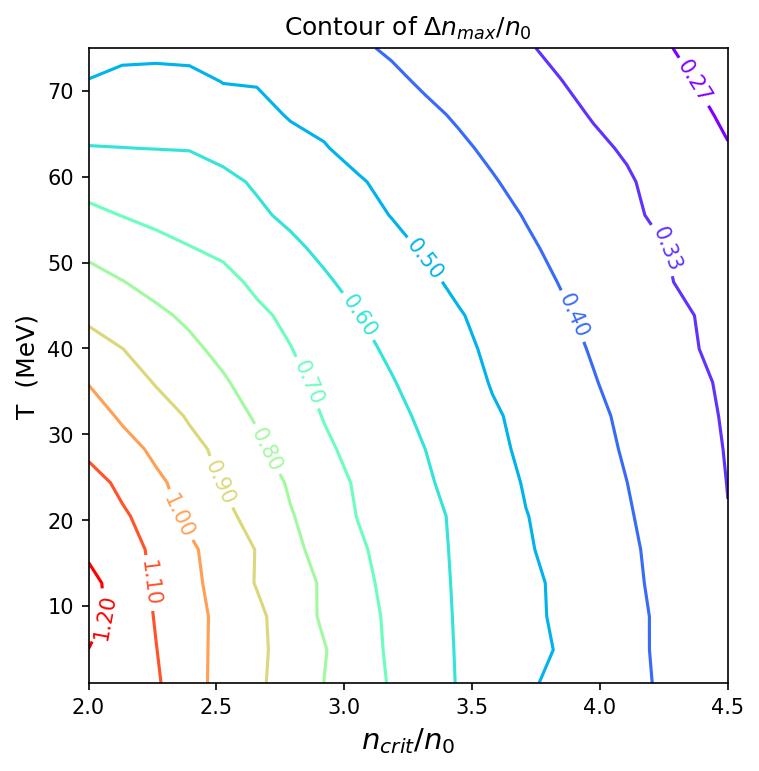

In [16]:
plt.figure(figsize=[5.5, 5.5])
plt.rcParams["figure.dpi"] = 150

# Plotting
T_grid, nc_grid = np.meshgrid(TT, nc)  # note BB first for x, TT for 

#V_old = np.load("DelP_T_B180_ms100.npy")
#D_grid_old, T_grid_old = np.meshgrid(np.linspace(1e6, 1e8, N)/4e8, np.linspace(1, 30, N))

contours = plt.contour(nc_grid/n0, T_grid, Deln.T/n0, levels = np.array([0.27, 0.33, 0.4, 0.5, 0.6, 0.7, 0.8, 0.9, 1.0, 1.1, 1.2]), cmap="rainbow")
plt.clabel(contours, inline=True, fontsize=10)

plt.title(r"Contour of $\Delta n_{max} / n_0$" )
plt.xlabel(r"$n_{crit} / n_0$", fontsize=14)
plt.ylabel("T  (MeV)", fontsize=12)

plt.savefig("Deln_max_list.pdf", dpi=300)  # Increase DPI as needed

In [8]:
Deln_max_list.min()/n0, Deln_max_list.max()/n0

(np.float64(0.2786404500042061), np.float64(3.904526837055905))

In [21]:
Deln_max_list[0,0]/n0

np.float64(1.2830763581470523)

# Prior to Aug 20

* Numerically solving for velocity using rasing runtime error

#### $a(0)=a_{Q^*}$, $a(+\infty) = 0$ as requirements and try to meet $a^\prime(0) = -v\frac{a_N - a_{Q^*}}{D_Q}$

In [267]:
import numpy as np
from scipy.integrate import solve_bvp
import matplotlib.pyplot as plt

# --- Constants ---
T       = 8.0
muQ     = 524.0
aQ      = 0.29       # a_Q^*
aN      = 0.42
alpha_s = 0.3
c1      = aQ         # L = c1
v_input = 2.3497050233918824e-7  # to test

# --- Microphysics ---
g_s  = np.sqrt(4 * np.pi * alpha_s)
etaQ = (9 * np.pi**2 * T**2) / muQ**2
tauQ = 1.98e12 * ((300.0 / muQ)**5)

qD   = np.sqrt(3 * g_s**2 * muQ**2 / (2 * np.pi**2))
h    = 1.81317
part1 = h * T**(5/3) / qD**(2/3)
part2 = (np.pi**3 * T**2) / (12.0 * qD)
DQ    = 1.0 / ((24.0 * alpha_s**2 / np.pi) * (part1 + part2))

# κ(v) from the linearized tail (NOTE: ηQ appears under the radical)
def get_kappa(v):
    return 2.0 * DQ / (-v + np.sqrt(v*v + 4.0 * DQ * etaQ / tauQ))

# Nonlinearity
def R(a):
    a_safe = np.clip(a, -7e2, 7e2)
    return (a_safe**3 + etaQ * a_safe) / tauQ

# ---------- Correct mapped ODE ----------
# State: y[0] = a(t), y[1] = p(t) = da/dx  (physical slope)
# Mapping: t = c1(1 - e^{-x/κ})  =>  dx/dt = κ/(c1 - t)
def ode_system(t, y, v, kappa):
    a  = y[0]
    p  = y[1]
    dxdt = kappa / (c1 - t)                 # dx/dt
    a_t  = p * dxdt                         # da/dt = (da/dx)*(dx/dt)
    p_t  = ((v * p + R(a)) / DQ) * dxdt     # dp/dt = (a_xx)*(dx/dt)
    return np.vstack((a_t, p_t))

# Boundary conditions: a(0) = aQ, a(c1) = 0
def bc(ya, yb):
    return np.array([ya[0] - aQ, yb[0]])

def get_derivatives_at_zero(v, return_solution=False, plot=False, verb=False):
    kappa = get_kappa(v)
    t = np.linspace(0, c1 - 1e-8, 800)

    # Initial guess: smooth, monotone
    a_guess = aQ * np.exp(-5.0 * t / c1)
    a_t_guess = -5.0 * aQ / c1 * np.exp(-5.0 * t / c1)
    # p = a_x = a_t * (dt/dx) with dt/dx = (c1 - t)/κ
    p_guess = a_t_guess * (c1 - t) / kappa
    y_init  = np.vstack((a_guess, p_guess))

    try:
        sol = solve_bvp(lambda tt, yy: ode_system(tt, yy, v, kappa), bc, t, y_init, max_nodes=100000)
        if sol.status != 0:
            raise RuntimeError("solve_bvp failed")

        # Physical slope at x=0 is p(0)
        a_prime_x0 = sol.y[1, 0]
        # a_t at t=0 if needed: a_t = a_x / (dt/dx), with (dt/dx)|_{t=0}=c1/κ
        a_prime_t0 = a_prime_x0 / ( (c1) / kappa )
        a_end = sol.y[0,-1]

        if verb:
            print(f" v = {v:.3e}")
            print(f"a'(t=0) = {a_prime_t0:.4e}")
            print(f"a'(x=0) = {a_prime_x0:.4e}")
            print(f"a(infty) = {a_end:.4e}")

        if plot:
            # a(t)
            plt.figure(figsize=(10, 4))
            plt.subplot(1, 2, 1)
            plt.plot(sol.x, sol.y[0])
            plt.xlabel(r"$t$")
            plt.ylabel(r"$a(t)$")
            plt.title("Profile in Transformed Space")
            plt.grid()

            # a(x) on the mapped mesh (stable)
            t_plot = sol.x
            x_plot = -kappa * np.log(1.0 - t_plot / c1)
            plt.subplot(1, 2, 2)
            plt.plot(x_plot, sol.y[0])
            plt.xlabel(r"$x$")
            plt.ylabel(r"$a(x)$")
            plt.title("Profile in Physical Space")
            plt.grid()

            plt.tight_layout()
            plt.show()

        if return_solution:
            return a_prime_x0, a_prime_t0, sol
        else:
            return a_prime_x0, a_prime_t0

    except Exception as e:
        if verb:
            print(f"Solver failed for v = {v:.2e}: {e}")
        return None, None

 v = 3.200e-07
a'(t=0) = -2.1536e+00
a'(x=0) = -1.7771e-07
a(infty) = -4.1960e-28


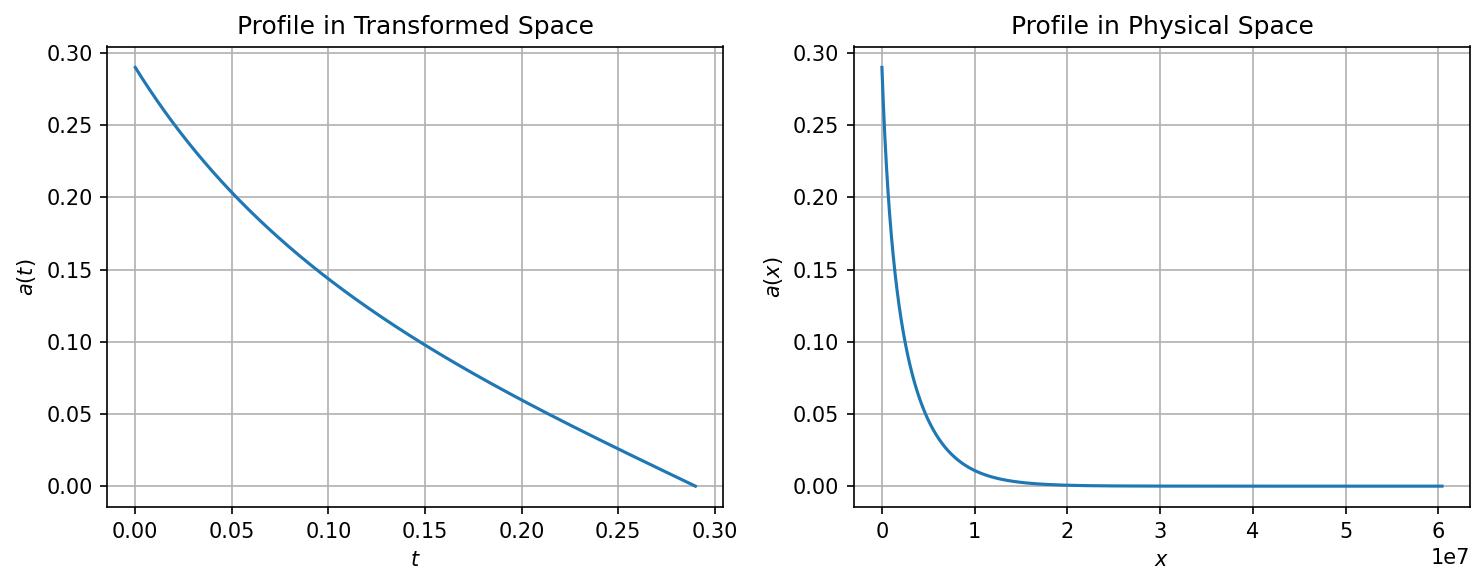

In [268]:
# new
a_prime_x0, a_prime_xtilde0, sol = get_derivatives_at_zero(v=96/ 3e8, return_solution=True, plot=True, verb=True)

Converged: v = 9.888421194951e-07
 v = 9.888e-07
a'(t=0) = -3.0351e+00
a'(x=0) = -1.3184e-07
a(infty) = -3.6850e-28


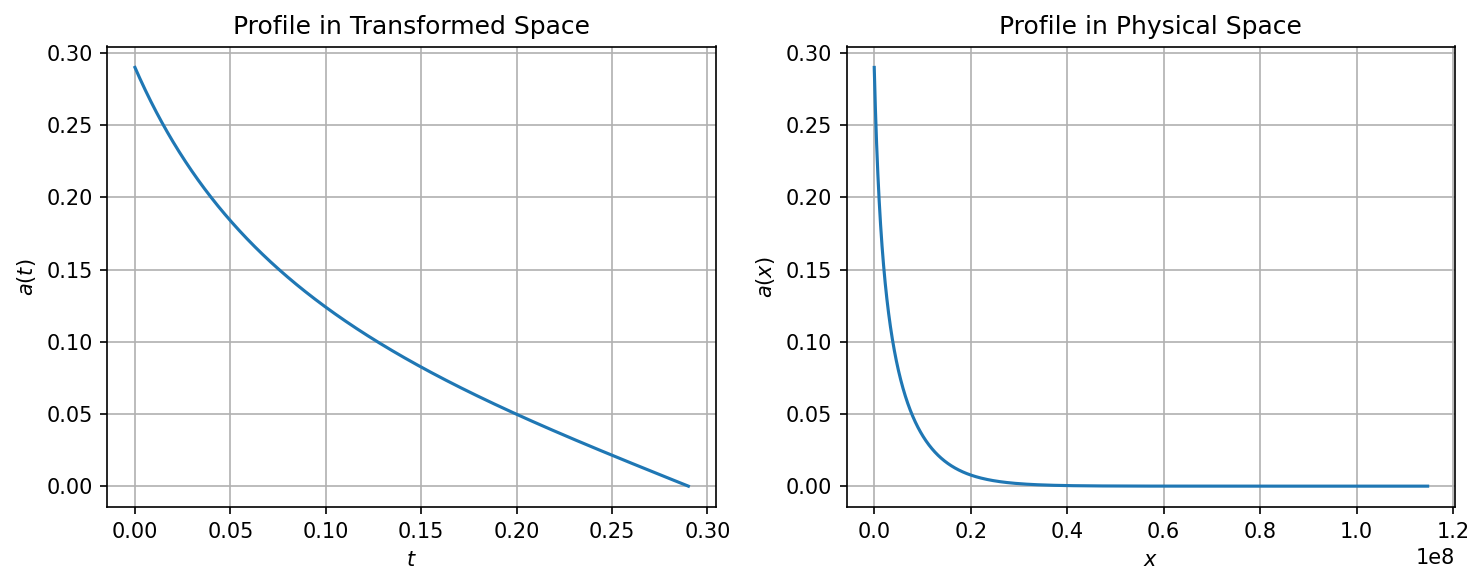

In [292]:
# new
from scipy.optimize import root

def slope_residual(v_arr):
    v = float(np.abs(v_arr[0]))  # extract scalar from array
    a_prime_x0, _ = get_derivatives_at_zero(v)
    if a_prime_x0 is None:
        return np.inf  # large penalty on failure
    rhs = -v * (aN - aQ) / DQ  # correct sign (check this is your definition)
    return a_prime_x0 - rhs

# --- Root solve ---
v_guess = 1e-7
sol = root(slope_residual, [v_guess], method='hybr')

if sol.success:
    v_root = float(np.abs(sol.x[0]))
    print(f"Converged: v = {v_root:.12e}")
    get_derivatives_at_zero(v_root, plot=True, verb=True)
else:
    raise RuntimeError(f" Root finding failed: {sol.message}")

In [4]:
import numpy as np
from scipy.integrate import solve_bvp
from scipy.optimize import root

def _vNtoQ_formula(T, aQstar, aN=1.0, muQ=360):
    '''
    Computes the phase boundary velocity for burning nuclear matter to quark matter

    Parameters:
    - T      : temperature
    - aQstar : normalized kaon isospin density at the boundary, range from 0 ~ 1
    - aN     : normalized kaon isospin density in nuclear matter, default = 1.0
    - muQ    : quark chemical potential, default = 360 MeV

    Returns:
    - velocity of phase boundary in meters per second

    '''
    alpha_s = 0.3
    g_s = np.sqrt(4 * np.pi * alpha_s)

    # Compute intermediate quantities
    etaQ = (9 * np.pi**2 * T**2) / muQ**2
    tauQ = 1.98e12 * ((300 / muQ)**5)
    qD = np.sqrt(3 * g_s**2 * muQ**2 / (2 * np.pi**2))
    h = 1.81317

    part1 = h*T**(5/3)/qD**(2/3)
    part2 = np.pi**3 * T**2 / (12*qD)

    DQ = 1/( 24*alpha_s**2/np.pi * ( part1 + part2 ) )
    # DQ = (np.pi / (24 * (0.3)**2 * 1.81 * T**(5/3))) * ((6 * 0.3 / np.pi * muQ**2)**(1/3))

    # Compute v_N->Q
    if aN < aQstar:
        print("hit aN < aQstar, returning velocity = 0")
        return 0.0
    else:
        return np.sqrt((DQ / tauQ) * ((aQstar**4 + 2 * etaQ * aQstar**2) / (2 * aN * (aN - aQstar)))) * 3e8

def _vNtoQ_num(T, aQstar, aN, muQ):
    alpha_s = 0.3
    c1 = aQstar

    # --- microphysics ---
    g_s   = np.sqrt(4*np.pi*alpha_s)
    etaQ  = (9*np.pi**2 * T**2) / muQ**2
    tauQ  = 1.98e12 * ((300.0 / muQ)**5)

    qD    = np.sqrt(3 * g_s**2 * muQ**2 / (2 * np.pi**2))
    h     = 1.81317
    part1 = h * T**(5/3) / qD**(2/3)
    part2 = (np.pi**3 * T**2) / (12.0 * qD)
    DQ    = 1.0 / ((24.0 * alpha_s**2 / np.pi) * (part1 + part2))

    # kappa(v) from the linearized tail (η_Q must be present!)
    def get_kappa(v):
        return 2 * DQ / (-v + np.sqrt(v*v + 4 * DQ * etaQ / tauQ))

    # Nonlinearity
    def R(a):
        a_safe = np.clip(a, -7e2, 7e2)
        return (a_safe**3 + etaQ * a_safe) / tauQ

    # ODE in t = \tilde{x}: y[0]=a(t), y[1]=p(t)=da/dx
    def ode_system(t, y, v, kappa):
        a = y[0]
        p = y[1]
        dxdt = kappa / (c1 - t)                # dx/dt
        a_t  = p * dxdt
        p_t  = ((v * p + R(a)) / DQ) * dxdt
        return np.vstack((a_t, p_t))

    # Boundary conditions: a(0)=aQ*, a(c1)=0
    def bc(ya, yb):
        return np.array([ya[0] - aQstar, yb[0]])

    # Solve BVP for a given v and return a'(x=0)=p(0)
    def get_derivatives_at_zero(v):
        v = float(abs(v))
        kappa = get_kappa(v)
        t = np.linspace(0, c1 - 1e-9, 1000)

        # Smooth monotone initial guess
        a_guess = aQstar * np.exp(-5 * t / c1)
        # p = a' = a_t / (dt/dx), with dt/dx = (c1 - t)/kappa
        p_guess = -(5 * aQstar / c1) * np.exp(-5 * t / c1) * (c1 - t) / kappa
        y_init  = np.vstack((a_guess, p_guess))

        try:
            sol = solve_bvp(lambda tt, yy: ode_system(tt, yy, v, kappa),
                            bc, t, y_init, max_nodes=100000)
            if sol.status != 0:
                return None
            return sol.y[1, 0]   # p(0) = a'(x=0)
        except Exception:
            return None

    # Residual for remaining BC at x=0: a'(0+) = - v (aN - aQ*) / DQ
    def slope_residual(v_arr):
        v = float(abs(v_arr[0]))          # root() passes arrays
        a_prime_x0 = get_derivatives_at_zero(v)
        if a_prime_x0 is None or not np.isfinite(a_prime_x0):
            return np.array([1e20], dtype=float)   # 1-element array
        rhs = -v * (aN - aQstar) / DQ
        return np.array([a_prime_x0 - rhs], dtype=float)

    # Solve for v (natural units), then convert to m/s for backward compatibility
    sol = root(slope_residual, [1e-7], method='hybr')
    if sol.success and sol.x[0] > 0:
        v_nat = float(abs(sol.x[0]))      # c = 1 units
        return v_nat * 3e8                # return m/s as your original code did
    else:
        raise RuntimeError(f" Root finding failed: {sol.message}")

In [218]:
9.888421194951e-07 * 3e8

296.65263584853

In [5]:
# new
_vNtoQ_num(T = 8, aQstar = 0.29, aN = 0.42, muQ = 524) 

296.65263584688836

In [2]:
import RMFsolver.phase_velocity as xxx
xxx._vNtoQ_num(T = 8, aQstar = 0.29, aN = 0.42, muQ = 524) 

296.65263584688836

In [236]:
# example sweep (returns v in natural units; convert to m/s in the plot)
muQ = 300.0
aN  = 0.8
aQ_vals = np.linspace(0.01, 0.49, 30)
T_vals  = np.hstack([np.linspace(1, 10, 12), np.linspace(11, 60, 8)])

AQS, TT = np.meshgrid(aQ_vals, T_vals)
V_num = np.full_like(AQS, np.nan, dtype=float)
V_ana = np.full_like(AQS, np.nan, dtype=float)
V_ratio = np.full_like(AQS, np.nan, dtype=float)

for i in range(TT.shape[0]):
    for j in range(TT.shape[1]):
        try:
            v_ana = _vNtoQ_formula(TT[i, j], AQS[i, j], aN, muQ)
            v_num = _vNtoQ_num(TT[i, j], AQS[i, j], aN, muQ)
            V_ana[i, j] = v_ana  
            V_num[i, j] = v_num  
            V_ratio[i, j] = v_ana / v_num 
            
        except Exception:
            pass

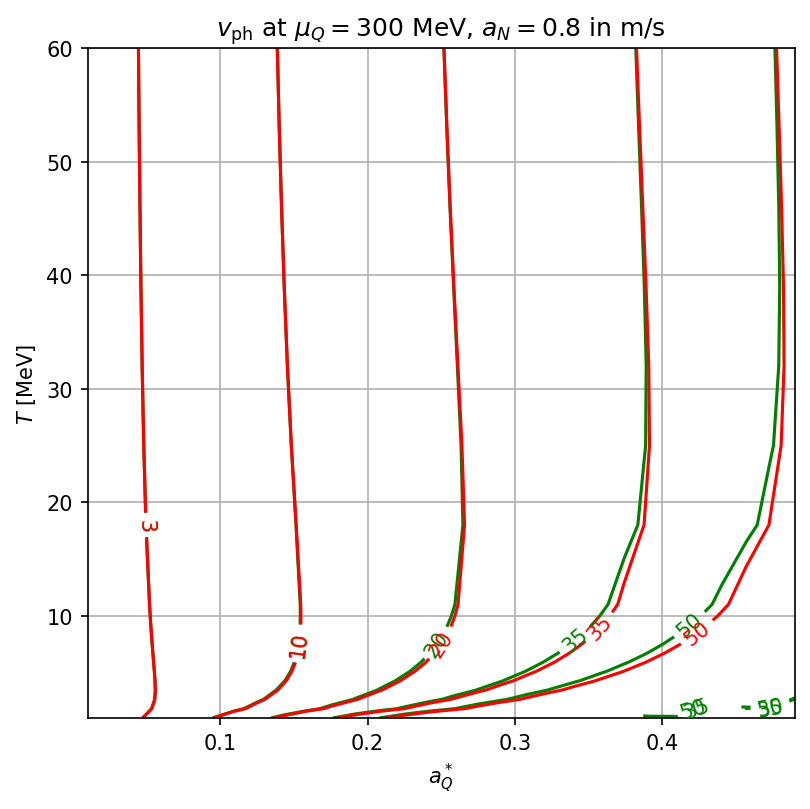

In [286]:
import matplotlib.pyplot as plt
levels = [3,10,20,35,50]
plt.figure(figsize=[5.5, 5.5])
plt.rcParams["figure.dpi"] = 150
cs = plt.contour(AQS, TT, V_num, levels=levels, colors='green')
cs2 = plt.contour(AQS, TT, V_ana, levels=levels, colors='red')
plt.clabel(cs, fmt='%d')
plt.clabel(cs2, fmt='%d')
plt.xlabel(r"$a_Q^*$")
plt.ylabel(r"$T$ [MeV]")
plt.title(r"$v_{\rm ph}$ at $\mu_Q=300$ MeV, $a_N=0.8$ in m/s")
plt.grid(True); plt.tight_layout(); plt.show()
#plt.savefig("1.pdf")

#### $a(0)=a_{Q^*}$, $a^\prime(0) = -v\frac{a_N - a_{Q^*}}{D_Q}$ as requirements and try to meet  $a(+\infty) = 0$

v* = 9.888419240738e-07


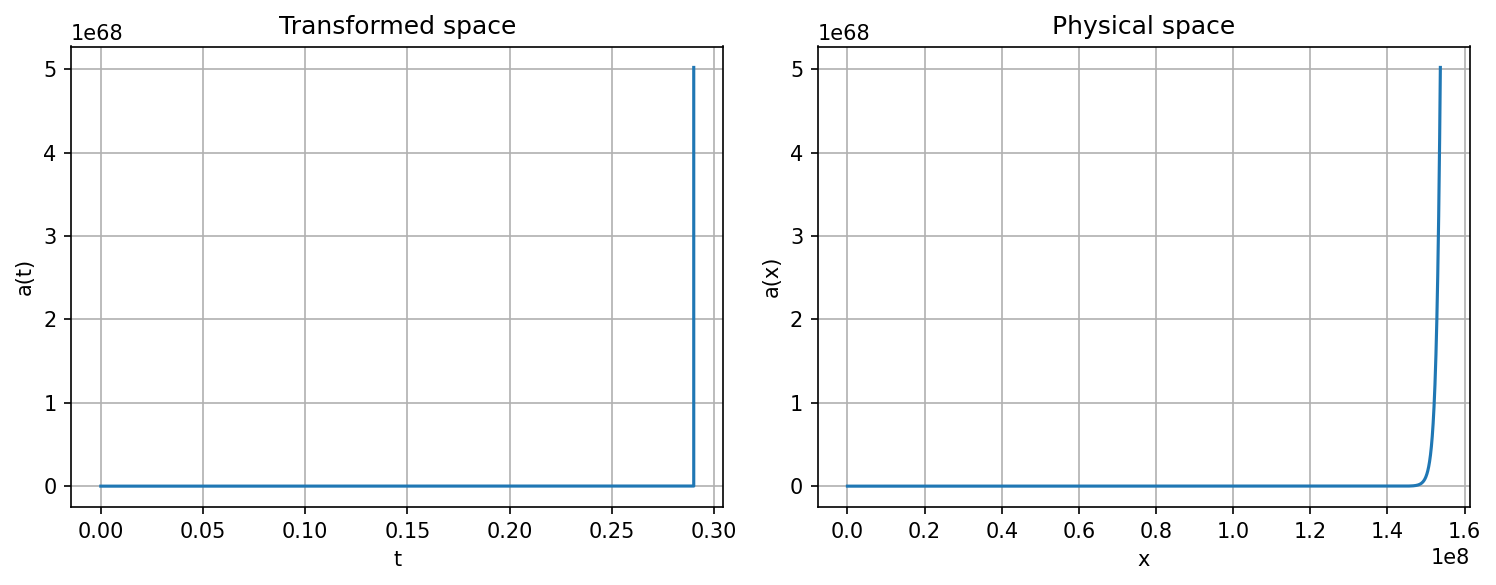

In [282]:
import numpy as np
from scipy.integrate import solve_ivp
from scipy.optimize import root_scalar
import matplotlib.pyplot as plt

# --- Constants ---
T       = 8.0
muQ     = 524.0
aQ      = 0.29
aN      = 0.42
alpha_s = 0.3
c1      = aQ

# --- Microphysics ---
g_s  = np.sqrt(4*np.pi*alpha_s)
etaQ = (9*np.pi**2 * T**2) / muQ**2
tauQ = 1.98e12 * ((300.0 / muQ)**5)

qD   = np.sqrt(3 * g_s**2 * muQ**2 / (2 * np.pi**2))
h    = 1.81317
part1 = h * T**(5/3) / qD**(2/3)
part2 = (np.pi**3 * T**2) / (12.0 * qD)
DQ    = 1.0 / ((24.0 * alpha_s**2 / np.pi) * (part1 + part2))

def get_kappa(v):
    # ηQ MUST be under the radical
    return 2.0 * DQ / (-v + np.sqrt(v*v + 4.0 * DQ * etaQ / tauQ))

def R(a):
    # tighter clipping prevents a**3 overflow if the IVP wanders
    a_safe = np.clip(a, -100.0, 100.0)
    return (a_safe**3 + etaQ * a_safe) / tauQ

# ODE: state y=[a, p],  p = da/dx ;  dx/dt = κ/(c1 - t)
def make_ode(v):
    kappa = get_kappa(v)
    eps = 1e-12 * c1
    def f(t, y):
        a, p = y
        denom = np.maximum(c1 - t, eps)
        dxdt  = kappa / denom
        a_t   = p * dxdt
        p_t   = ((v * p + R(a)) / DQ) * dxdt
        return [a_t, p_t]
    return f, kappa

# Integrate to t=L-ε and return a(L; v)
def shoot_aL(v, method='Radau'):
    f, kappa = make_ode(v)
    p0 = -v * (aN - aQ) / DQ             # BC at x=0
    t0, t1 = 0.0, c1 * (1 - 1e-10)       # never hit t=c1 exactly
    try:
        sol = solve_ivp(f, (t0, t1), [aQ, p0],
                        method=method, rtol=1e-6, atol=1e-9,
                        dense_output=False, max_step=(t1 - t0) / 200)
        if not sol.success or not np.isfinite(sol.y[0, -1]):
            return np.nan
        return sol.y[0, -1]
    except Exception:
        return np.nan

# Residual for root finding: want a(L; v) = 0
def residual(v):
    return shoot_aL(float(v))

# ---------- Auto‑bracket then solve ----------
# 1) try to bracket on a log grid
v_grid = np.geomspace(1e-9, 1e-6, 50)
vals   = []
for v in v_grid:
    fv = residual(v)
    vals.append((v, fv))
# prune NaNs
vals = [(v, f) for (v, f) in vals if np.isfinite(f)]

bracket = None
for (v0, f0), (v1, f1) in zip(vals[:-1], vals[1:]):
    if f0 == 0.0:
        bracket = (v0*0.9, v0*1.1); break
    if f1 == 0.0:
        bracket = (v1*0.9, v1*1.1); break
    if f0 * f1 < 0:
        bracket = (v0, v1); break

if bracket is not None:
    rs = root_scalar(residual, method='brentq', bracket=bracket, maxiter=120)
    if not rs.converged:
        raise RuntimeError("Brentq failed after bracketing.")
    v_star = float(rs.root)
else:
    # 2) no sign change found — fall back to secant using the two smallest |f|
    if len(vals) < 2:
        raise RuntimeError("Could not evaluate residual to form a bracket or secant start.")
    vals_sorted = sorted(vals, key=lambda x: abs(x[1]))
    x0, x1 = vals_sorted[0][0], vals_sorted[1][0]
    rs = root_scalar(residual, method='secant', x0=x0, x1=x1, maxiter=300)
    if not rs.converged:
        raise RuntimeError("Secant fallback failed to converge.")
    v_star = float(rs.root)

print(f"v* = {v_star:.12e}")

# ---------- Optional: integrate once at v* and plot ----------
f_star, kappa_star = make_ode(v_star)
t0, t1 = 0.0, c1 * (1 - 1e-10)
p0 = -v_star * (aN - aQ) / DQ
sol = solve_ivp(f_star, (t0, t1), [aQ, p0], method='Radau',
                rtol=1e-7, atol=1e-10, dense_output=True)

if sol.success:
    t = sol.t
    a = sol.y[0]
    x = -kappa_star * np.log(1 - t / c1)

    fig, ax = plt.subplots(1, 2, figsize=(10, 4))
    ax[0].plot(t, a); ax[0].set_xlabel('t'); ax[0].set_ylabel('a(t)'); ax[0].grid(); ax[0].set_title('Transformed space')
    ax[1].plot(x, a); ax[1].set_xlabel('x'); ax[1].set_ylabel('a(x)'); ax[1].grid(); ax[1].set_title('Physical space')
    plt.tight_layout(); plt.show()

* do FIG.4 in the old paper [1404.5279] but using actual numbers
* play with plt.contour and see interplation
* do a simpler version of "simulation" of two boundaries chasing each other, plot $z(t)$: first obtain the slope $\frac{dP}{dr}$ or $\frac{dn}{dr}$
* find out $v\sim z$ as $\Delta n\to 0$
* (Alex) use numerical method vNtoQ_num to plot the 2x2 grid and see

# Prior to Aug 27

In [2]:
import numpy as np
import time
import matplotlib.pyplot as plt
from scipy.integrate import quad
from scipy.optimize import fsolve, approx_fprime, root_scalar, root, least_squares
from numdifftools import Gradient, Derivative
import RMFsolver.constants as const
import RMFsolver.RMFparameter as para
from RMFsolver.Solver import RMFsolve_mu, RMFpressureSYM, RMFpressurePNM, pressure_RMF
from RMFsolver.phase_velocity import P_f, vNtoQ_Pc, vNtoQ_B, vNtoQ_nc, PQM, PQM_em, Get_Delta_n_max, _find_muB_muK_star

def PNM(mu_B, Temp, param=para.paraQMCRMF3, ):
    pre = RMFpressurePNM(
        input_num = mu_B,
        input_type = "muB", 
        Trmf = Temp, 
        para = param, 
        sigma_init = 30, 
        w0_init = 20, 
        r03_init = -3, 
        mub_init = 990,
        verb = False
        )
    return float(pre.item())

def PNM_n(nB, Temp):
    pre = RMFpressurePNM(
        input_num = nB,
        input_type = "nB", 
        Trmf = Temp, 
        para = param, 
        sigma_init = 30, 
        w0_init = 20, 
        r03_init = -3, 
        mub_init = 990,
        verb = False
        )
    return float(pre.item())

n0 = 0.16 * const.MeV_fm**3

In [3]:
T = 15
n_crit = 2.5 * n0
Deln = 0.05 * n_crit
m_s = 0
param = para.paraQMCRMF3
NM_type = "PNM"
method = "numerical"

# solve for bag constant
P_crit = PNM_n(n_crit, T)
P_diff = lambda x: PNM(x, T) - P_crit
muB_crit = fsolve(P_diff, 1050)[0]
PQM_solve_for_B = lambda x: PQM(muB_crit, 0, x, T, m_s) - P_crit
B_SQM = fsolve(PQM_solve_for_B, 180)[0]

# solve for points Q and N at beta eq.
DelP = PNM_n(n_crit + Deln, T) - P_crit
PNM_minus_PShift = lambda x: PNM(x,T) - P_crit - DelP
muB_N = fsolve(PNM_minus_PShift, 1050)[0]

PQM_minus_Pshift = lambda x: PQM(x, 0, B_SQM, T, m_s) - P_crit - DelP
muB_Q = fsolve(PQM_minus_Pshift, 1050)[0]

# calculating aQstar
if method == "numerical":
    epsilon = np.sqrt(np.finfo(float).eps)
    muB_star, muK_star = _find_muB_muK_star(PQM, P_crit + DelP, muB_N, B_SQM, T, m_s)
    PQM_wrap = lambda Mu: PQM(Mu[0], Mu[1], B_SQM, T, m_s)
    grad_Qstar = approx_fprime(np.array([muB_star, muK_star]), PQM_wrap, epsilon)
    nB_Qstar = grad_Qstar[0]
    nK_Qstar = grad_Qstar[1]
    grad_Q = approx_fprime(np.array([muB_Q, 0]), PQM_wrap, epsilon)
    nB_Q = grad_Q[0]
    nK_Q = grad_Q[1]
    aQstar = (nK_Qstar - nK_Q)/nB_Q  

elif method == "analytical":
    PQM_muB = lambda Mu: PQM(Mu, 0, B_SQM, T, m_s)
    PQM_muK = lambda Mu: PQM(muB_Q, Mu, B_SQM, T, m_s)
    ddPQM_ddmuK = Derivative(PQM_muK, n=2)
    dPQM_dmuK = Derivative(PQM_muK, n=1)
    dPQM_dmuB = Derivative(PQM_muB, n=1)
    chiK_Q = ddPQM_ddmuK(0)
    nB_Q = dPQM_dmuB(muB_Q)
    nK_Q = dPQM_dmuK(0)
    aQstar = np.sqrt(2*(muB_N - muB_Q)*chiK_Q / nB_Q)
    muK_star = np.sqrt(2 * nB_Q * (muB_N - muB_Q) / chiK_Q)
    PQM_solve_for_muBstar = lambda x: PQM(x, muK_star, B_SQM, T, m_s) - P_crit
    muB_star = fsolve(PQM_solve_for_muBstar, muB_Q)[0]

else:
    raise RuntimeError(f"Input method unknown")

# calculating aN
PNM_wrap = lambda x: PNM(x, T)
dPNM_dmuB = Derivative(PNM_wrap, n=1)
nB_N = dPNM_dmuB(muB_N)
aN = (nB_N - nK_Q) / nB_Q   

muQ = muB_star/3

alpha_s = 0.3
g_s = np.sqrt(4 * np.pi * alpha_s)

# Compute intermediate quantities
etaQ = (9 * np.pi**2 * T**2) / muQ**2
tauQ = 1.98e12 * ((300 / muQ)**5)
qD = np.sqrt(3 * g_s**2 * muQ**2 / (2 * np.pi**2))
h = 1.81317

part1 = h*T**(5/3)/qD**(2/3)
part2 = np.pi**3 * T**2 / (12*qD)

DQ = 1/( 24*alpha_s**2/np.pi * ( part1 + part2 ) )
# DQ = (np.pi / (24 * (0.3)**2 * 1.81 * T**(5/3))) * ((6 * 0.3 / np.pi * muQ**2)**(1/3))

# Compute v_N->Q
vNQ = np.sqrt((DQ / tauQ) * ((aQstar**4 + 2 * etaQ * aQstar**2) / (2 * aN * (aN - aQstar)))) * 3e8

print(" muQ       =", muQ, ';\n', "aQstar    =", aQstar, ';\n', "aN        =", aN, ';\n', "vNQ       =", vNQ, "/(3*^8);")

 muQ       = 372.0714739241407 ;
 aQstar    = 0.24087906496549236 ;
 aN        = 0.596646438272634 ;
 vNQ       = 39.427986088206076 /(3*^8);


In [35]:
P_crit, DelP, muB_Q, muB_N, muK_star, muB_star

(2033898368.834574,
 230150426.4333856,
 np.float64(1475.3808988272394),
 np.float64(1499.1624236199702),
 131.7713258223774,
 1451.3068705975213)

In [4]:
from RMFsolver.phase_velocity import PQM, extract_contour_coords_num, extract_contour_coords_ana
import numpy as np
import matplotlib.pyplot as plt

muK_lim= 90

muK_list = np.linspace(-muK_lim, muK_lim, 100)
muB_coords, muK_coords = extract_contour_coords_ana(lambda x, y:PQM(x, y, B_SQM, 15, 0), (1050, 1150), muK_list, level=P_crit+DelP, )

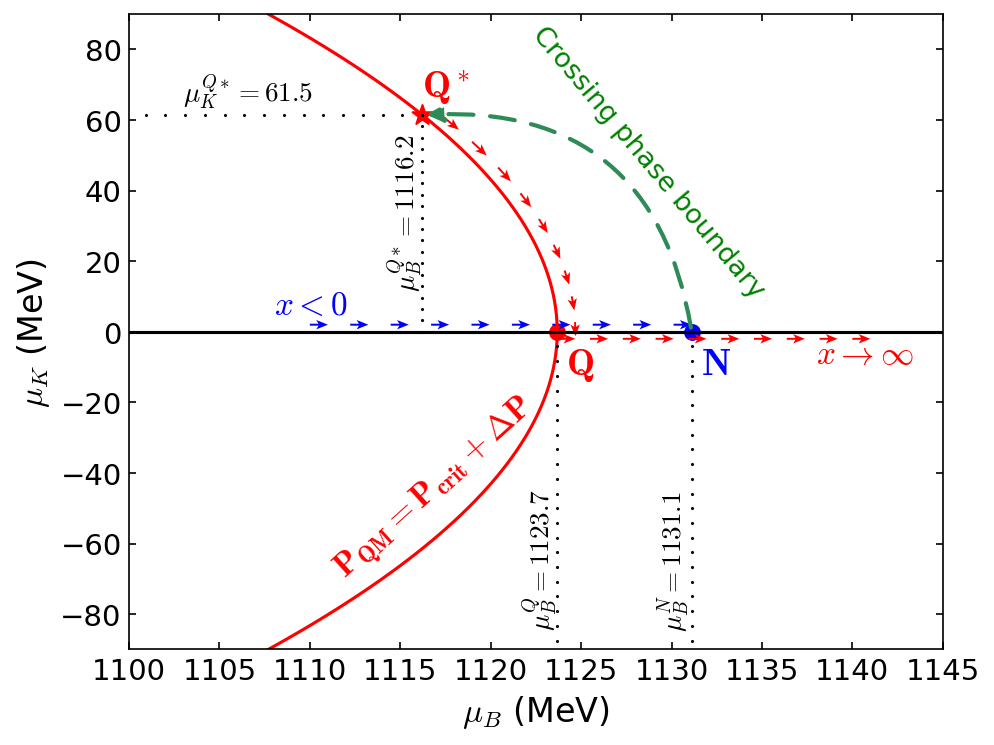

In [13]:
import matplotlib as mpl
import matplotlib.pyplot as plt
import numpy as np

factor = 1.2

plt.figure(figsize=[7, 5.5])
plt.rcParams["figure.dpi"] = 150
mpl.rcParams.update({
    "mathtext.fontset": "cm",   # Use Computer Modern for math only
    "mathtext.rm": "serif",
    "mathtext.it": "serif:italic",
    "mathtext.bf": "serif:bold",
    "xtick.labelsize": 14,
    "ytick.labelsize": 14,
})

plt.plot(muB_coords, muK_coords, 'r')
plt.plot(np.linspace(1095, 1145, 100), np.zeros(100), 'k')
plt.xlim(1100, 1145)
plt.ylim(-muK_lim, muK_lim)

#plt.title(r"Isobar for $T=15$ MeV, $n_{crit} = 2.5 n_0$, $\Delta n = n_0/8$", fontsize=14)
plt.xlabel(r"$\mu_B$ (MeV)", fontsize=16)
plt.ylabel(r"$\mu_K$ (MeV)", fontsize=16)

plt.scatter(muB_Q, 0, s=50, c='r')
plt.text(muB_Q+0.5, -12, r"$\mathbf{Q}$", c='r', fontsize=18)

plt.scatter(muB_N, 0, s=50, c='b')
plt.text(muB_N+0.5, -12, r"$\mathbf{N}$", c='b', fontsize=18)

plt.scatter(muB_star, muK_star, s=100, c='r', marker='*')
plt.text(muB_star, muK_star+5, r"$\mathbf{Q^*}$", c='r', fontsize=18)

plt.plot(muB_Q*np.ones(25), np.linspace(-100, 0, 25), ".", markersize=1, color='k')
plt.text(muB_Q-2.0, -82, rf"$\mu_B^Q = {muB_Q:.1f}$", rotation=90, fontsize=13)

plt.plot(muB_N*np.ones(25), np.linspace(-100, 0, 25), ".", markersize=1, color='k')
plt.text(muB_N-2.0, -82, rf"$\mu_B^N = {muB_N:.1f}$", rotation=90, fontsize=13)

plt.plot(muB_star*np.ones(20), np.linspace(0, muK_star, 20), ".", markersize=1, color='k')
plt.text(muB_star-2.0, 14, rf"$\mu_B^{{Q*}} = {muB_star:.1f}$", rotation=90, fontsize=13)

plt.plot(np.linspace(1090, muB_star, 25), muK_star*np.ones(25), ".", markersize=1, color='k')
plt.text(1103, muK_star+4, rf"$\mu_K^{{Q*}} = {muK_star:.1f}$", fontsize=13)

plt.text(1111, -69, rf"$\mathbf{{P_{{QM}} = P_{{crit}} + \Delta P}}$", rotation=42, c='r', fontsize=16)

# arrows from Q to
plt.text(1108, 5, rf"$x<0$", c='b', fontsize=16)
x1 = np.linspace(muB_Q, 1140, 10)
y1 = np.full_like(x1, -2)         # vertical offset only
u1 = np.full_like(x1, 1.0)          # horizontal length in data units
v1 = np.zeros_like(x1)              # no vertical component
plt.quiver(
    x1, y1, u1, v1,
    angles='xy', scale_units='xy', scale=1,
    color='r',
    width=0.002 * factor,       # shaft thicker
    headwidth=4 * factor,       # head wider
    headlength=5 * factor,      # head longer
    headaxislength=4 * factor,  # axis length
    linewidths=0.6 * factor     # outline thicker
)

# from  to N
plt.text(1138, -9, rf"$x\to\infty$", c='r', fontsize=16)
x2 = np.linspace(1110, muB_N-1, 10)
y2 = np.full_like(x1, 2)         # vertical offset only
u2 = np.full_like(x1, 1.0)          # horizontal length in data units
v2 = np.zeros_like(x1)              # no vertical component
plt.quiver(
    x2, y2, u2, v2,
    angles='xy', scale_units='xy', scale=1,
    color='b',
    width=0.002 * factor,       # shaft thicker
    headwidth=4 * factor,       # head wider
    headlength=5 * factor,      # head longer
    headaxislength=4 * factor,  # axis length
    linewidths=0.6 * factor     # outline thicker
)

# --- arrows along the red isobar FROM Q* -> Q (bigger + offset) ---
# indices closest to Q* and Q on the curve
i_star = np.argmin(np.abs(muK_coords - muK_star))
i_Q    = np.argmin(np.abs(muK_coords - 0.0))   # Q is at mu_K = 0

# always march from Q* to Q
sign = 1 if i_Q > i_star else -1
seg_len = abs(i_Q - i_star)
step = max(1, seg_len // 8)                     # ~8 arrows; smaller -> denser
idx = np.arange(i_star, i_Q, sign * step)
idx_next = idx + sign                           # forward neighbor

# tangent (Q* -> Q)
dX = muB_coords[idx_next] - muB_coords[idx]
dY = muK_coords[idx_next] - muK_coords[idx]

# unit tangent
L = np.hypot(dX, dY)
tx = np.zeros_like(dX); ty = np.zeros_like(dY)
m = L > 0
tx[m] = dX[m] / L[m]
ty[m] = dY[m] / L[m]

# pick a fixed length in data units
arrow_len = 4.0
U = arrow_len * tx
V = arrow_len * ty

# offset arrows off the curve along the normal
nx = np.zeros_like(tx); ny = np.zeros_like(ty)
nx[m] = -ty[m]            # normal = (-ty, tx)
ny[m] =  tx[m]

offset = 1.0              # <-- move arrows away from line; flip sign if needed
X = muB_coords[idx] + offset * nx
Y = muK_coords[idx] + offset * ny

plt.quiver(
    X, Y, U, V,
    angles='xy', scale_units='xy', scale=1,
    color='r',
    width=0.002 * factor,       # shaft thicker
    headwidth=4 * factor,       # head wider
    headlength=5 * factor,      # head longer
    headaxislength=4 * factor,  # axis length
    linewidths=0.6 * factor     # outline thicker
)


from matplotlib.patches import FancyArrowPatch
ax = plt.gca()

plt.text(1122, 10, rf"Crossing phase boundary", c='g', fontsize=13, rotation=130+180)
arc = FancyArrowPatch(
    (muB_N, 0), (muB_star, muK_star),
    connectionstyle="arc3,rad=0.45",   # ↑ bigger → more “up”; flip sign if wrong way
    arrowstyle="-|>", mutation_scale=16,
    linestyle=(0,(6,4)), lw=2, color="seagreen", zorder=3
)
ax.add_patch(arc)

plt.tick_params(which='both', direction='in', top=True, right=True)

#plt.savefig("muB_muK_Plane.pdf", bbox_inches="tight")

In [6]:
import numpy as np
from scipy.integrate import solve_bvp
import matplotlib.pyplot as plt

# --- Constants ---
T       = 15.0
muQ     = 372.0714739241407
aQ      = 0.24087906496549236       # a_Q^*
aN      = 0.596646438272634
alpha_s = 0.3
c1      = aQ         # L = c1
v_input = 2.3497050233918824e-7  # to test

# --- Microphysics ---
g_s  = np.sqrt(4 * np.pi * alpha_s)
etaQ = (9 * np.pi**2 * T**2) / muQ**2
tauQ = 1.98e12 * ((300.0 / muQ)**5)

qD   = np.sqrt(3 * g_s**2 * muQ**2 / (2 * np.pi**2))
h    = 1.81317
part1 = h * T**(5/3) / qD**(2/3)
part2 = (np.pi**3 * T**2) / (12.0 * qD)
DQ    = 1.0 / ((24.0 * alpha_s**2 / np.pi) * (part1 + part2))

# κ(v) from the linearized tail (NOTE: ηQ appears under the radical)
def get_kappa(v):
    return 2.0 * DQ / (-v + np.sqrt(v*v + 4.0 * DQ * etaQ / tauQ))

# Nonlinearity
def R(a):
    a_safe = np.clip(a, -7e2, 7e2)
    return (a_safe**3 + etaQ * a_safe) / tauQ

# ---------- Correct mapped ODE ----------
# State: y[0] = a(t), y[1] = p(t) = da/dx  (physical slope)
# Mapping: t = c1(1 - e^{-x/κ})  =>  dx/dt = κ/(c1 - t)
def ode_system(t, y, v, kappa):
    a  = y[0]
    p  = y[1]
    dxdt = kappa / (c1 - t)                 # dx/dt
    a_t  = p * dxdt                         # da/dt = (da/dx)*(dx/dt)
    p_t  = ((v * p + R(a)) / DQ) * dxdt     # dp/dt = (a_xx)*(dx/dt)
    return np.vstack((a_t, p_t))

# Boundary conditions: a(0) = aQ, a(c1) = 0
def bc(ya, yb):
    return np.array([ya[0] - aQ, yb[0]])

def get_derivatives_at_zero(v, return_solution=False, plot=False, verb=False):
    kappa = get_kappa(v)
    t = np.linspace(0, c1 - 1e-8, 800)

    # Initial guess: smooth, monotone
    a_guess = aQ * np.exp(-5.0 * t / c1)
    a_t_guess = -5.0 * aQ / c1 * np.exp(-5.0 * t / c1)
    # p = a_x = a_t * (dt/dx) with dt/dx = (c1 - t)/κ
    p_guess = a_t_guess * (c1 - t) / kappa
    y_init  = np.vstack((a_guess, p_guess))

    try:
        sol = solve_bvp(lambda tt, yy: ode_system(tt, yy, v, kappa), bc, t, y_init, max_nodes=100000)
        if sol.status != 0:
            raise RuntimeError("solve_bvp failed")

        # Physical slope at x=0 is p(0)
        a_prime_x0 = sol.y[1, 0]
        # a_t at t=0 if needed: a_t = a_x / (dt/dx), with (dt/dx)|_{t=0}=c1/κ
        a_prime_t0 = a_prime_x0 / ( (c1) / kappa )
        a_end = sol.y[0,-1]

        if verb:
            print(f" v = {v:.3e}")
            print(f"a'(t=0) = {a_prime_t0:.4e}")
            print(f"a'(x=0) = {a_prime_x0:.4e}")
            print(f"a(infty) = {a_end:.4e}")

        if plot:
            # a(t)
            plt.figure(figsize=(10, 4))
            plt.subplot(1, 2, 1)
            plt.plot(sol.x, sol.y[0])
            plt.xlabel(r"$t$")
            plt.ylabel(r"$a(t)$")
            plt.title("Profile in Transformed Space")
            plt.grid()

            # a(x) on the mapped mesh (stable)
            t_plot = sol.x
            x_plot = -kappa * np.log(1.0 - t_plot / c1)
            plt.subplot(1, 2, 2)
            plt.plot(x_plot, sol.y[0])
            plt.xlabel(r"$x$")
            plt.ylabel(r"$a(x)$")
            plt.title("Profile in Physical Space")
            plt.grid()

            plt.tight_layout()
            plt.show()

        if return_solution:
            return a_prime_x0, a_prime_t0, np.array([-kappa * np.log(1.0 - sol.x / c1), sol.y[0]])
        else:
            return a_prime_x0, a_prime_t0

    except Exception as e:
        if verb:
            print(f"Solver failed for v = {v:.2e}: {e}")
        return None, None

Converged: v = 1.330592460348e-07
 v = 1.331e-07
a'(t=0) = -1.1405e+00
a'(x=0) = -1.9249e-07
a(infty) = 4.5661e-28


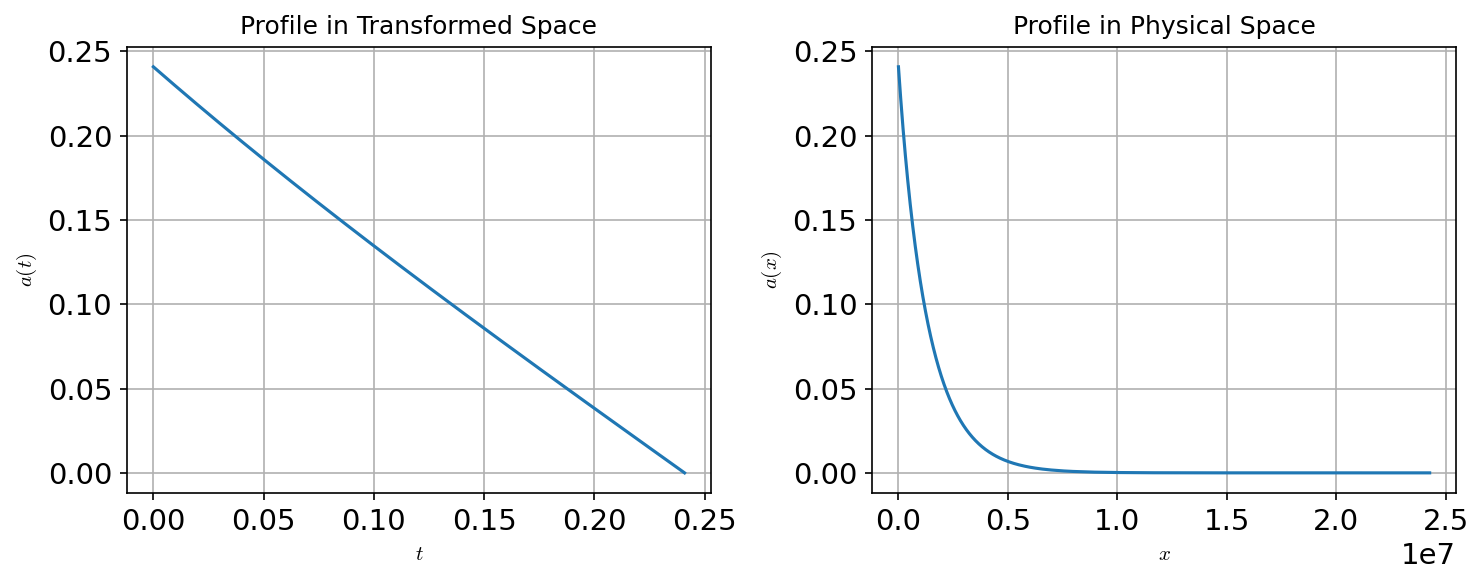

In [7]:
# new
from scipy.optimize import root

def slope_residual(v_arr):
    v = float(np.abs(v_arr[0]))  # extract scalar from array
    a_prime_x0, _ = get_derivatives_at_zero(v)
    if a_prime_x0 is None:
        return np.inf  # large penalty on failure
    rhs = -v * (aN - aQ) / DQ  # correct sign (check this is your definition)
    return a_prime_x0 - rhs

# --- Root solve ---
v_guess = 1e-7
sol = root(slope_residual, [v_guess], method='hybr')

if sol.success:
    v_root = float(np.abs(sol.x[0]))
    print(f"Converged: v = {v_root:.12e}")
    _, _, sol_list = get_derivatives_at_zero(v_root, plot=True, verb=True, return_solution=True)
else:
    raise RuntimeError(f" Root finding failed: {sol.message}")

In [14]:
from RMFsolver.phase_velocity import _vNtoQ_num as v_num
v_num(T=15.0, aQstar = aQ, aN = aN, muQ = muB_star/3) / 3e+8

1.330592460348002e-07

In [9]:
sol_list[0,:] = sol_list[0,:]*const.MeV_fm / 1e6

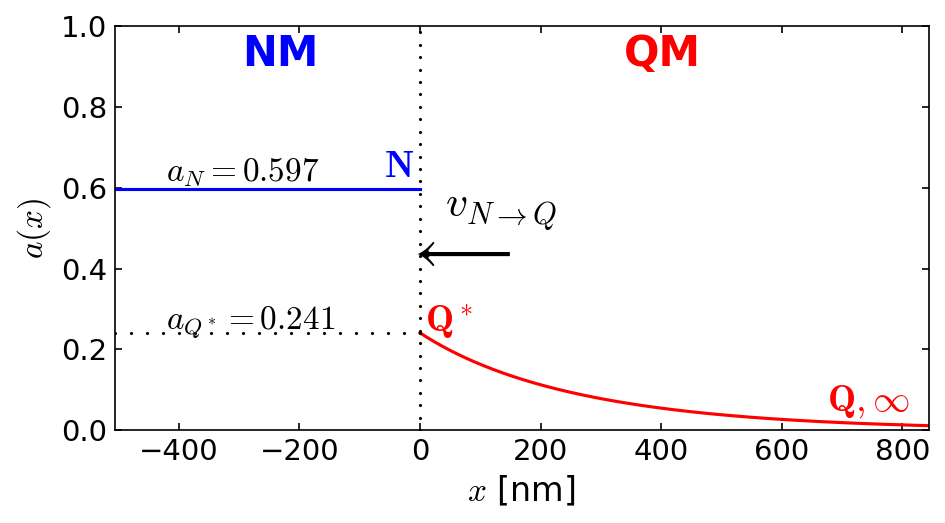

In [16]:
import matplotlib as mpl
import matplotlib.pyplot as plt
import numpy as np

factor = 1.2

plt.figure(figsize=[7, 3.5])
plt.rcParams["figure.dpi"] = 150
mpl.rcParams.update({
    "mathtext.fontset": "cm",   # Use Computer Modern for math only
    "mathtext.rm": "serif",
    "mathtext.it": "serif:italic",
    "mathtext.bf": "serif:bold",
    "xtick.labelsize": 14,
    "ytick.labelsize": 14,
})

NN = 760

x_lim_min = -sol_list[0, :NN].max() * 0.6
x_lim_max = sol_list[0, :NN].max()
y_lim_min = 0
y_lim_max = 1.0

x_greater_0 = sol_list[0, :NN] 
a_greater_0 = sol_list[1, :NN]
plt.plot(x_greater_0, a_greater_0, 'r')
plt.plot(np.linspace(x_lim_min, 0, NN), aN * np.ones(NN), 'b')

plt.plot(np.zeros(40), np.linspace(0,1.2,40), '.', markersize=1, color='k')
plt.plot(np.linspace(x_lim_min, 0, 20), aQ*np.ones(20), '.', markersize=1, color='k')

plt.xlim(x_lim_min, x_lim_max)
plt.ylim(y_lim_min, y_lim_max)

plt.xlabel(rf"$x$ [nm]", fontsize=16)
plt.ylabel(rf"$a(x)$", fontsize=16)
#plt.title(rf"$a(x)$ profile for $T=15$ MeV, $n_{{crit}} = 2.5 n_0$, $\Delta n = n_0/8$", fontsize=14)

plt.text(0.01*x_lim_max, 1.01*aQ, rf"$\mathbf{{Q^*}}$", c='r', fontsize=18)
plt.text(x_lim_max*0.8, 0.05, rf"$\mathbf{{Q, \infty}}$", c='r', fontsize=18)
plt.text(-x_lim_max*0.07, 1.05*aN, rf"$\mathbf{{N}}$", c='b', fontsize=18)
plt.text(-x_lim_max*0.35, 0.9, rf"NM", c='b', fontsize=20, fontweight="bold")
plt.text(x_lim_max*0.4, 0.9, rf"QM", c='r', fontsize=20, fontweight="bold")
plt.text(-x_lim_max*0.5, aN*1.03, rf"$a_N = {aN:.3f}$", fontsize=16)
plt.text(-x_lim_max*0.5, aQ*1.05, rf"$a_{{Q^*}} = {aQ:.3f}$", fontsize=16)

plt.text(-x_lim_max*0.1, 0.4, rf"$\overset{{\qquad v_{{N\to Q}}}}{{\longleftarrow}}$", fontsize=30)

plt.tick_params(which='both', direction='in', top=True, right=True)

plt.savefig("a(x)_Profile.pdf", bbox_inches="tight")

In [79]:
from RMFsolver.phase_velocity import vNtoQ_nc
import RMFsolver.constants as const

n0 = 0.16 * const.MeV_fm**3
m_s = 0
param = para.paraQMCRMF3
NM_type = "PNM"
method = "numerical"

start = time.time()
ve, _ = vNtoQ_nc(
    T = 72.0,
    n_crit = 2 * n0,
    Deln = 0.5 * n0,
    m_s = 0.0,
    param = para.paraQMCRMF3,
    NM_type = "PNM",
    method = "numerical"
)
end = time.time()

ve, end - start

(np.float64(961.9204929088443), 3.5575013160705566)

In [63]:
Deln_cut3

array([72.        , 70.31961154, 68.97058824, 67.55314826, 65.94117647,
       64.83001602, 62.91176471, 62.13473258])

Text(0, 0.5, 'Temperature [MeV]')

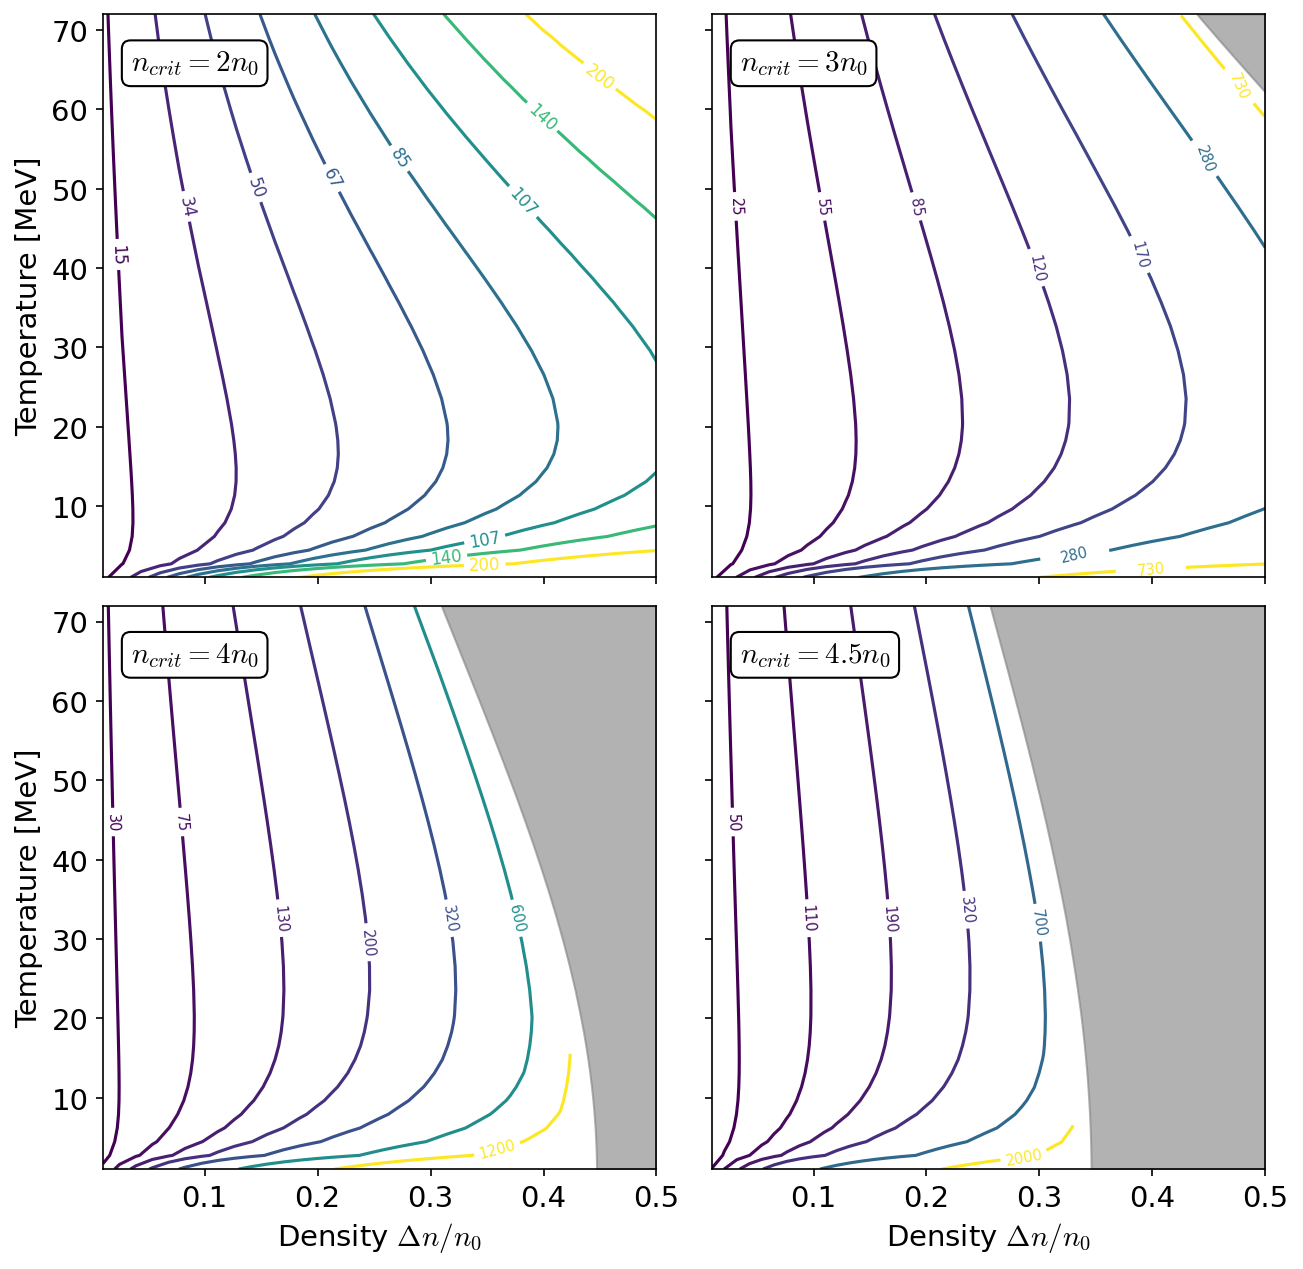

In [13]:
import numpy as np
import matplotlib.pyplot as plt
import time
from scipy.integrate import quad
from scipy.interpolate import interp1d
from scipy.optimize import fsolve, approx_fprime, root_scalar, root, least_squares
from numdifftools import Gradient, Derivative
import RMFsolver.constants as const
import RMFsolver.RMFparameter as para
from RMFsolver.Solver import RMFsolve_mu, RMFpressureSYM, RMFpressurePNM, pressure_RMF
from RMFsolver.phase_velocity import P_f, n_B, vNtoQ_nc, vNtoQ_B, PQM

#plt.figure(figsize=[5.5, 5.5])
plt.rcParams["figure.dpi"] = 150

# Define n0 (adjust as needed)
n0 = 0.16 * const.MeV_fm**3

nc2, nc3, nc4, nc5 = 2*n0, 3*n0, 4*n0, 4.5*n0
N = 30

al = 0.6

# shaded region
Deln_cut3, T_cut3 = np.load("Shade_n_crit=3.0.npy")
Cut3 = interp1d(T_cut3, Deln_cut3, kind='linear', fill_value="extrapolate")

Deln_cut4, T_cut4 = np.load("Shade_n_crit=4.0.npy")
Cut4 = interp1d(T_cut4, Deln_cut4, kind='linear', fill_value="extrapolate")

Deln_cut4_5, T_cut4_5 = np.load("Shade_n_crit=4.5.npy")
Cut4_5 = interp1d(T_cut4_5, Deln_cut4_5, kind='linear', fill_value="extrapolate")


# create plots
fig, axs = plt.subplots(2, 2, figsize=(10, 10), sharex=True, sharey=True)
plt.subplots_adjust(wspace=0.1, hspace=0.05)


# n_crit = 2 * n0
TT = np.hstack([np.linspace(1, 20, int(N*2/5)),np.linspace(20.5, 72, int(N*3/5))])
D2 = np.linspace(0.01*n0, 0.5*n0, N)
V2 = np.load("v_n_crit=2.0.npy")
cs = axs[0,0].contour(D2/n0, TT, V2, levels=np.array([15, 34, 50, 67, 85, 107, 140, 200]))
axs[0,0].clabel(cs, inline=True, fontsize=8)
#ax.set_title(r"$n_{crit} = $"+ncrits[idx])
axs[0,0].annotate(r"$n_{crit} = 2n_0$", xy=(0.05, 0.9), xycoords='axes fraction', fontsize=14, bbox=dict(boxstyle="round,pad=0.3", fc="white", ec="black"))


# n_crit = 3 * n0
# ----- n_crit = 3 * n0 -----
V3  = np.load("v_n_crit=3.0.npy")
t   = np.linspace(0.0, 1.0, N)
# work in ABSOLUTE density using nc3 (not n0)
Dlo  = 0.01 * n0
Dhi  = 0.5  * n0
Dmax = np.minimum(0.5 * n0, Cut3(TT) - 0.015 * n0)  
Dmax = np.maximum(Dmax, Dlo)
# grids that match V3's (i,j) layout
D_grid = Dlo + (Dmax - Dlo)[:, None] * t[None, :]            # shape (N, N)
T_grid = np.repeat(TT[:, None], N, axis=1)
Z = V3
# shaded region: Cut3(T) → 0.5 * nc3, plotted as Δn/n_crit
Dcut = Cut3(TT)                    # shape (N,)
Dhi  = 0.5 * n0 * np.ones_like(TT)
axs[0,1].fill_betweenx(
    TT, Dcut/n0, Dhi/n0, color="grey", alpha=al, zorder=0
)
levels3 = np.array([25, 55, 85, 120, 170, 280, 730])
cs = axs[0,1].contour(D_grid/n0, T_grid, Z, levels=levels3, zorder=1)
axs[0,1].clabel(cs, inline=True, fontsize=7)
axs[0,1].set_xlim(0.01, 0.5)
axs[0,1].set_ylim(1, 72)
axs[0,1].annotate(r"$n_{crit} = 3 n_0$", xy=(0.05, 0.9),
                  xycoords='axes fraction', fontsize=14,
                  bbox=dict(boxstyle="round,pad=0.3", fc="white", ec="black"))


# n_crit = 4 * n0
# ----- n_crit = 3 * n0 -----
V4  = np.load("v_n_crit=4.0.npy")
t   = np.linspace(0.0, 1.0, N)
# work in ABSOLUTE density using nc3 (not n0)
Dlo  = 0.01 * n0
Dhi  = 0.5  * n0
Dmax = np.minimum(0.5 * n0, Cut4(TT) - 0.015 * n0)  
Dmax = np.maximum(Dmax, Dlo)
# grids that match V3's (i,j) layout
D_grid = Dlo + (Dmax - Dlo)[:, None] * t[None, :]            # shape (N, N)
T_grid = np.repeat(TT[:, None], N, axis=1)
Z = V4
# shaded region: Cut3(T) → 0.5 * nc3, plotted as Δn/n_crit
Dcut = Cut4(TT)                    # shape (N,)
Dhi  = 0.5 * n0 * np.ones_like(TT)
axs[1,0].fill_betweenx(
    TT, Dcut/n0, Dhi/n0, color="grey", alpha=al, zorder=0
)
levels4 = np.array([30, 75, 130, 200, 320, 600, 1200])
cs = axs[1,0].contour(D_grid/n0, T_grid, Z, levels=levels4, zorder=1)
axs[1,0].clabel(cs, inline=True, fontsize=7)
axs[1,0].set_xlim(0.01, 0.5)
axs[1,0].set_ylim(1, 72)
axs[1,0].annotate(r"$n_{crit} = 4 n_0$", xy=(0.05, 0.9),
                  xycoords='axes fraction', fontsize=14,
                  bbox=dict(boxstyle="round,pad=0.3", fc="white", ec="black"))


# n_crit = 4.5 * n0
V4_5  = np.load("v_n_crit=4.5.npy")
t   = np.linspace(0.0, 1.0, N)
# work in ABSOLUTE density using nc3 (not n0)
Dlo  = 0.01 * n0
Dhi  = 0.5  * n0
Dmax = np.minimum(0.5 * n0, Cut4_5(TT) - 0.015 * n0)  
Dmax = np.maximum(Dmax, Dlo)
# grids that match V3's (i,j) layout
D_grid = Dlo + (Dmax - Dlo)[:, None] * t[None, :]            # shape (N, N)
T_grid = np.repeat(TT[:, None], N, axis=1)
Z = V4_5
# shaded region: Cut3(T) → 0.5 * nc3, plotted as Δn/n_crit
Dcut = Cut4_5(TT)                    # shape (N,)
Dhi  = 0.5 * n0 * np.ones_like(TT)
axs[1,1].fill_betweenx(
    TT, Dcut/n0, Dhi/n0, color="grey", alpha=al, zorder=0
)
levels4_4 = np.array([50, 110, 190, 320, 700, 2000])
cs = axs[1,1].contour(D_grid/n0, T_grid, Z, levels=levels4_4, zorder=1)
axs[1,1].clabel(cs, inline=True, fontsize=7)
axs[1,1].set_xlim(0.01, 0.5)
axs[1,1].set_ylim(1, 72)
axs[1,1].annotate(r"$n_{crit} = 4.5 n_0$", xy=(0.05, 0.9),
                  xycoords='axes fraction', fontsize=14,
                  bbox=dict(boxstyle="round,pad=0.3", fc="white", ec="black"))

axs[1, 0].set_xlabel(r"Density $\Delta n / n_0$", fontsize = 14)
axs[1, 1].set_xlabel(r"Density $\Delta n / n_0$", fontsize = 14)
axs[0, 0].set_ylabel("Temperature [MeV]", fontsize = 14)
axs[1, 0].set_ylabel("Temperature [MeV]", fontsize = 14)

#plt.savefig("2by2_Grid.pdf")

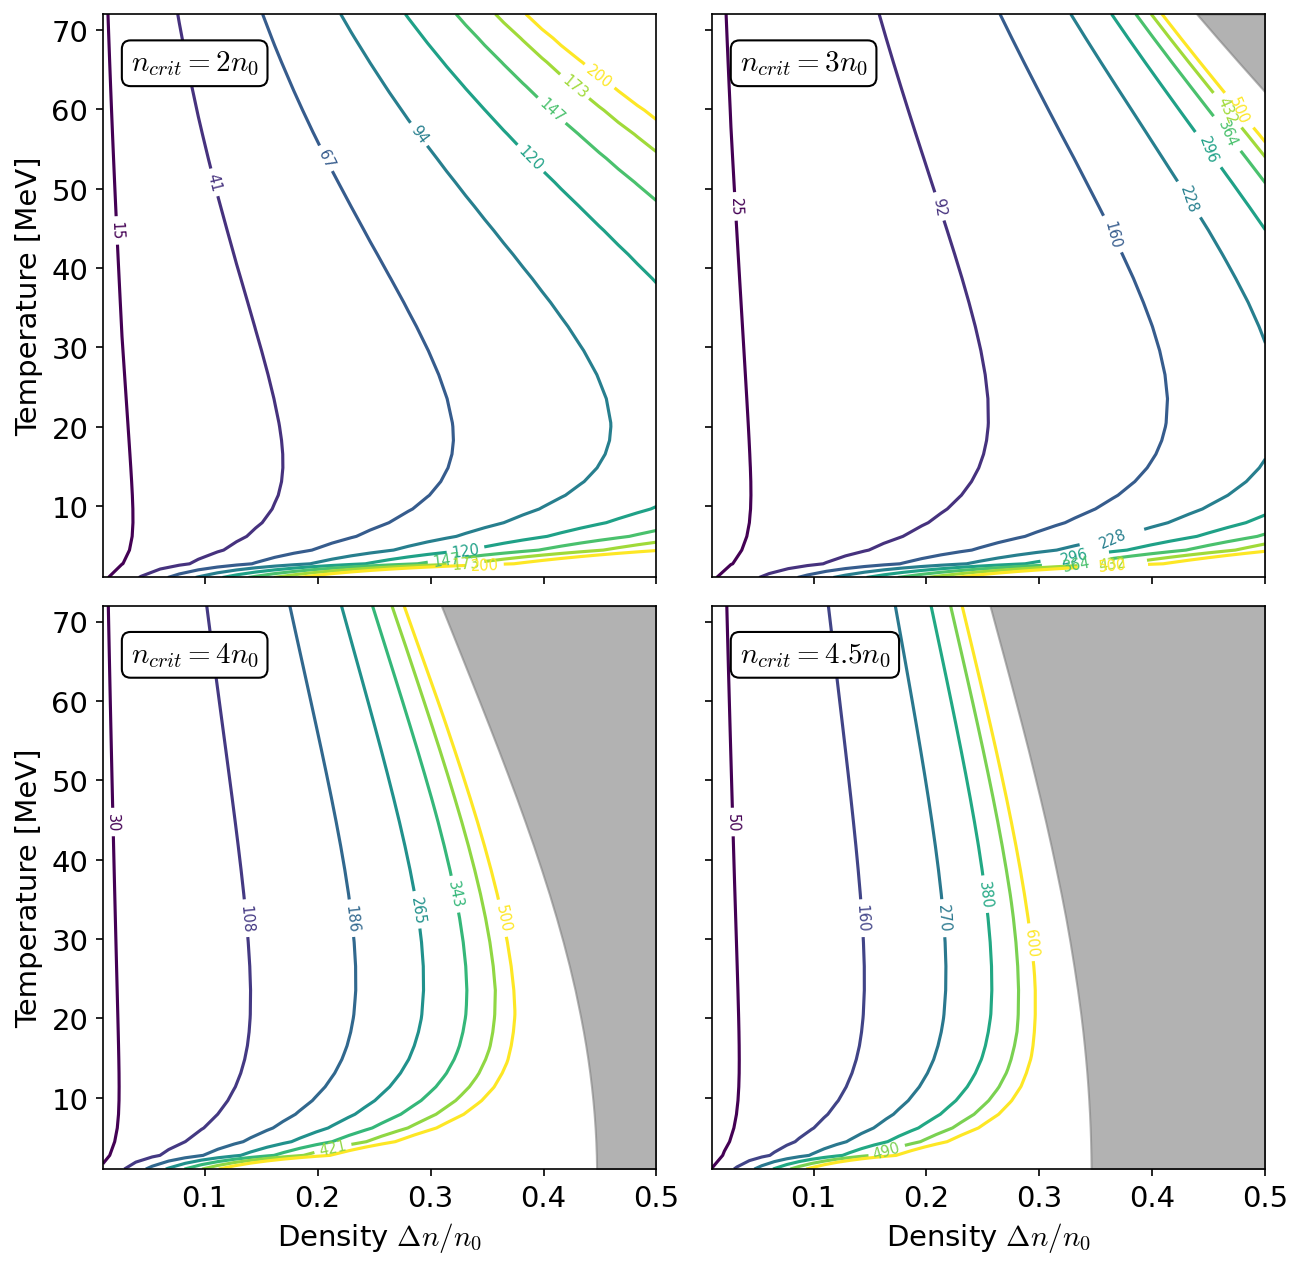

In [96]:
import numpy as np
import matplotlib.pyplot as plt
import time
from scipy.integrate import quad
from scipy.interpolate import interp1d
from scipy.optimize import fsolve, approx_fprime, root_scalar, root, least_squares
from numdifftools import Gradient, Derivative
import RMFsolver.constants as const
import RMFsolver.RMFparameter as para
from RMFsolver.Solver import RMFsolve_mu, RMFpressureSYM, RMFpressurePNM, pressure_RMF
from RMFsolver.phase_velocity import P_f, n_B, vNtoQ_nc, vNtoQ_B, PQM

# Define n0 (adjust as needed)
n0 = 0.16 * const.MeV_fm**3

nc2, nc3, nc4, nc5 = 2*n0, 3*n0, 4*n0, 4.5*n0
N = 30

al = 0.6

# shaded region
Deln_cut3, T_cut3 = np.load("Shade_n_crit=3.0.npy")
Cut3 = interp1d(T_cut3, Deln_cut3, kind='linear', fill_value="extrapolate")

Deln_cut4, T_cut4 = np.load("Shade_n_crit=4.0.npy")
Cut4 = interp1d(T_cut4, Deln_cut4, kind='linear', fill_value="extrapolate")

Deln_cut4_5, T_cut4_5 = np.load("Shade_n_crit=4.5.npy")
Cut4_5 = interp1d(T_cut4_5, Deln_cut4_5, kind='linear', fill_value="extrapolate")


# create plots
fig, axs = plt.subplots(2, 2, figsize=(10, 10), sharex=True, sharey=True)
plt.subplots_adjust(wspace=0.1, hspace=0.05)


# n_crit = 2 * n0
TT = np.hstack([np.linspace(1, 20, int(N*2/5)),np.linspace(20.5, 72, int(N*3/5))])
D2 = np.linspace(0.01*n0, 0.5*n0, N)
V2 = np.load("v_n_crit=2.0.npy")
cs = axs[0,0].contour(D2/n0, TT, V2, levels=np.linspace(15, 200, 8))
axs[0,0].clabel(cs, inline=True, fontsize=7, fmt="%d")
#ax.set_title(r"$n_{crit} = $"+ncrits[idx])
axs[0,0].annotate(r"$n_{crit} = 2n_0$", xy=(0.05, 0.9), xycoords='axes fraction', fontsize=14, bbox=dict(boxstyle="round,pad=0.3", fc="white", ec="black"))


# n_crit = 3 * n0
# ----- n_crit = 3 * n0 -----
V3  = np.load("v_n_crit=3.0.npy")
t   = np.linspace(0.0, 1.0, N)
# work in ABSOLUTE density using nc3 (not n0)
Dlo  = 0.01 * n0
Dhi  = 0.5  * n0
Dmax = np.minimum(0.5 * n0, Cut3(TT) - 0.015 * n0)  
Dmax = np.maximum(Dmax, Dlo)
# grids that match V3's (i,j) layout
D_grid = Dlo + (Dmax - Dlo)[:, None] * t[None, :]            # shape (N, N)
T_grid = np.repeat(TT[:, None], N, axis=1)
Z = V3
# shaded region: Cut3(T) → 0.5 * nc3, plotted as Δn/n_crit
Dcut = Cut3(TT)                    # shape (N,)
Dhi  = 0.5 * n0 * np.ones_like(TT)
axs[0,1].fill_betweenx(
    TT, Dcut/n0, Dhi/n0, color="grey", alpha=al, zorder=0
)
levels3 = np.linspace(25, 500, 8)
cs = axs[0,1].contour(D_grid/n0, T_grid, Z, levels=levels3, zorder=1)
axs[0,1].clabel(cs, inline=True, fontsize=7, fmt="%d")
axs[0,1].set_xlim(0.01, 0.5)
axs[0,1].set_ylim(1, 72)
axs[0,1].annotate(r"$n_{crit} = 3 n_0$", xy=(0.05, 0.9),
                  xycoords='axes fraction', fontsize=14,
                  bbox=dict(boxstyle="round,pad=0.3", fc="white", ec="black"))


# n_crit = 4 * n0
# ----- n_crit = 3 * n0 -----
V4  = np.load("v_n_crit=4.0.npy")
t   = np.linspace(0.0, 1.0, N)
# work in ABSOLUTE density using nc3 (not n0)
Dlo  = 0.01 * n0
Dhi  = 0.5  * n0
Dmax = np.minimum(0.5 * n0, Cut4(TT) - 0.015 * n0)  
Dmax = np.maximum(Dmax, Dlo)
# grids that match V3's (i,j) layout
D_grid = Dlo + (Dmax - Dlo)[:, None] * t[None, :]            # shape (N, N)
T_grid = np.repeat(TT[:, None], N, axis=1)
Z = V4
# shaded region: Cut3(T) → 0.5 * nc3, plotted as Δn/n_crit
Dcut = Cut4(TT)                    # shape (N,)
Dhi  = 0.5 * n0 * np.ones_like(TT)
axs[1,0].fill_betweenx(
    TT, Dcut/n0, Dhi/n0, color="grey", alpha=al, zorder=0
)
levels4 = np.linspace(30, 500, 7)
cs = axs[1,0].contour(D_grid/n0, T_grid, Z, levels=levels4, zorder=1)
axs[1,0].clabel(cs, inline=True, fontsize=7, fmt="%d")
axs[1,0].set_xlim(0.01, 0.5)
axs[1,0].set_ylim(1, 72)
axs[1,0].annotate(r"$n_{crit} = 4 n_0$", xy=(0.05, 0.9),
                  xycoords='axes fraction', fontsize=14,
                  bbox=dict(boxstyle="round,pad=0.3", fc="white", ec="black"))


# n_crit = 4.5 * n0
V4_5  = np.load("v_n_crit=4.5.npy")
t   = np.linspace(0.0, 1.0, N)
# work in ABSOLUTE density using nc3 (not n0)
Dlo  = 0.01 * n0
Dhi  = 0.5  * n0
Dmax = np.minimum(0.5 * n0, Cut4_5(TT) - 0.015 * n0)  
Dmax = np.maximum(Dmax, Dlo)
# grids that match V3's (i,j) layout
D_grid = Dlo + (Dmax - Dlo)[:, None] * t[None, :]            # shape (N, N)
T_grid = np.repeat(TT[:, None], N, axis=1)
Z = V4_5
# shaded region: Cut3(T) → 0.5 * nc3, plotted as Δn/n_crit
Dcut = Cut4_5(TT)                    # shape (N,)
Dhi  = 0.5 * n0 * np.ones_like(TT)
axs[1,1].fill_betweenx(
    TT, Dcut/n0, Dhi/n0, color="grey", alpha=al, zorder=0
)
levels4_4 = np.linspace(50, 600, 6)
cs = axs[1,1].contour(D_grid/n0, T_grid, Z, levels=levels4_4, zorder=1)
axs[1,1].clabel(cs, inline=True, fontsize=7, fmt="%d")
axs[1,1].set_xlim(0.01, 0.5)
axs[1,1].set_ylim(1, 72)
axs[1,1].annotate(r"$n_{crit} = 4.5 n_0$", xy=(0.05, 0.9),
                  xycoords='axes fraction', fontsize=14,
                  bbox=dict(boxstyle="round,pad=0.3", fc="white", ec="black"))

axs[1, 0].set_xlabel(r"Density $\Delta n / n_0$", fontsize = 14)
axs[1, 1].set_xlabel(r"Density $\Delta n / n_0$", fontsize = 14)
axs[0, 0].set_ylabel("Temperature [MeV]", fontsize = 14)
axs[1, 0].set_ylabel("Temperature [MeV]", fontsize = 14)

plt.savefig("2by2_Grid.pdf")

## Obtain $z(t)$ profile

In [3]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

# Read CSV (skip the header row if it exists)
df = pd.read_csv("pressure_of_radius_pMeV4.csv")

# Convert the first column (fractions as strings) to floats
radius = df.iloc[:, 0].apply(lambda s: eval(str(s)))  # turns "1/100000" into 1/100000.0
pressure = df.iloc[:, 1]

# Convert to numpy arrays if needed
radius = radius.to_numpy(dtype=float)
pressure = pressure.to_numpy(dtype=float)

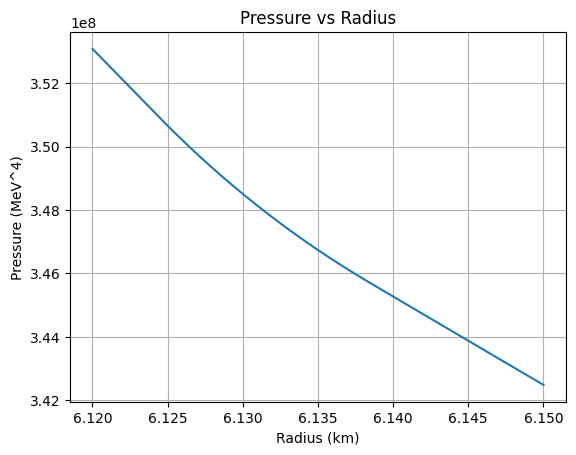

In [3]:
# Plot
plt.plot(radius[612000:615000], pressure[612000:615000])
plt.xlabel("Radius (km)")
plt.ylabel("Pressure (MeV^4)")
plt.title("Pressure vs Radius")
plt.grid(True)
plt.show()

#### calculate $z_{max}$

In [4]:
from RMFsolver.phase_velocity import Get_Delta_P_max

start = time.time()
Delta_P_max = Get_Delta_P_max(
    T = 15.0,
    P_crit = 3.542592408984268*1e8,
    m_s = 0,
    param = para.paraQMCRMF3,
    NM_type = "PNM",
    method = "numerical"
)
end = time.time()
Delta_P_max, end - start

(580805159.0733254, 28.349851846694946)

In [5]:
#Delta_P_max = 5.81e8
DelP_max_plus_P_crit = Delta_P_max + P_crit

idx = np.argmin(np.abs(pressure - DelP_max_plus_P_crit))
6.1 - radius[idx]

np.float64(0.9960899999999997)

In [6]:
P_crit/1e8, Delta_P_max/1e8

(3.542592408984268, 5.808051590733254)

#### Interpolate

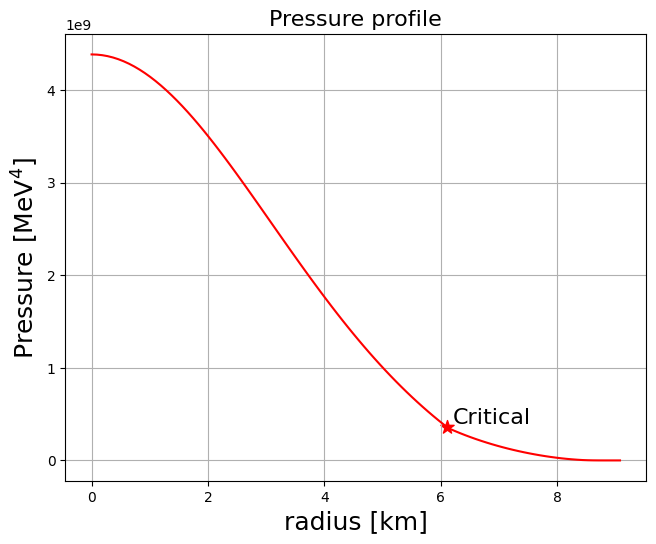

In [7]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from scipy.interpolate import interp1d
from fractions import Fraction

plt.figure(figsize=[7.5, 5.8])
plt.rcParams["figure.dpi"] = 150

P_of_r = interp1d(radius, pressure, kind="linear", fill_value="extrapolate")

r_test = np.linspace(radius.min(), radius.max(), 100)
P_test = np.array([P_of_r(ele) for ele in r_test])
plt.plot(r_test, P_test, 'r')
plt.scatter(6.1, P_of_r(6.1), marker="*", c='r', s=100)
plt.text(6.2, P_of_r(6.1)*1.1, rf"Critical", fontsize=16)
#plt.plot(radius, pressure, 'b')

plt.title("Pressure profile", fontsize = 16)
plt.xlabel(rf"radius [km]", fontsize = 18)
plt.ylabel(rf"Pressure [MeV$^4$]", fontsize = 18)
plt.grid()
plt.show()

In [24]:
P_of_r(z_crit - z0) / (Delta_P_max + P_crit)

np.float64(1.0000000000000002)

In [25]:
P_crit, Delta_P_max

(354259240.89842683, 580805159.0733254)

In [26]:
z0 = 1.0136903211671218
z_list = np.hstack([np.linspace(0, 0.08, 35), np.linspace(0.081, 0.8*z0, 15), np.linspace(0.8*z0, z0, 50)])
z_crit = 6.117599868035375
v_list = []
def vz_accurate(z):
    DelP_P_crit = P_of_r(z_crit - z)
    vel, _ = vNtoQ_Pc(T=15.0, P_crit = P_crit, DelP = DelP_P_crit - P_crit, m_s = 0, param = para.paraQMCRMF3, NM_type = "PNM", method = "numerical")
    return vel / 1e3 # in km/s

for i in range(len(z_list)):
    v_list.append(vz_accurate(z_list[i]))
    print(i)
    
v_list = np.array(v_list) # np.array([vz_accurate(z) for z in z_list])

0
1
2
3
4
5
6
7
8
9
10
11
12
13
14
15
16
17
18
19
20
21
22
23
24
25
26
27
28
29
30
31
32
33
34
35
36
37
38
39
40
41
42
43
44
45
46
47
48
49
50
51
52
53
54
55
56
57
58
59
60
61
62
63
64
65
66
67
68
69
70
71
72
73
74
75
76
77
78
79
80
81
82
83
84
85
86
87
88
89
90
91
92
93
94
95
96
97
98
99


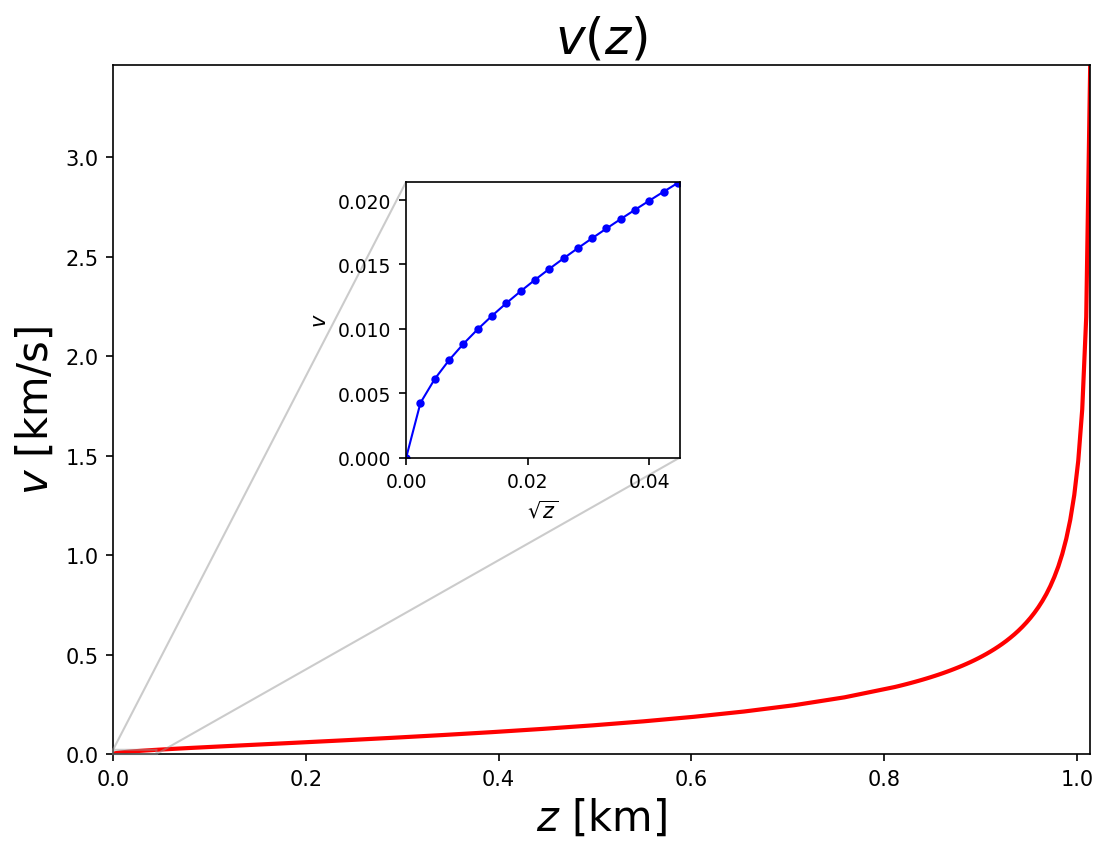

In [65]:
import numpy as np
import matplotlib.pyplot as plt
from mpl_toolkits.axes_grid1.inset_locator import inset_axes
from matplotlib.axes import Axes

vz_interp1d = interp1d(z_list, v_list, kind="linear", fill_value="extrapolate")

# --- main figure/axes ---
fig, ax = plt.subplots(figsize=(7.5, 5.8), dpi=150)

# main curve (keep your split if you need to skip a bad point around index 25)
ax.plot(z_list, np.array([vz_interp1d(z) for z in z_list]), 'r', lw=2)
#ax.plot(z_list[26:], v_list[26:], 'b', lw=2)

ax.set_xlabel(r"$z$ [km]", fontsize=20)
ax.set_ylabel(r"$v$ [km/s]", fontsize=20)
ax.set_title(r"$v(z)$", fontsize=24)
ax.set_xlim(0, z0)
ax.set_ylim(0, float(vz_interp1d(z0)))
#ax.set_yscale("log")

# -----------------------------
# inset (zoom near z=0)
# -----------------------------
# place inset by fractions of the main-axes (x0, y0, width, height)
# this puts it more centered (upper-middle). Tweak if you like.
axins: Axes = ax.inset_axes([0.30, 0.43, 0.28, 0.4])  # [left, bottom, width, height] in axes coords

# Option A: plot the SAME slices to avoid crossing lines
axins.plot(z_list[:20], np.array([vz_interp1d(z) for z in z_list])[:20], 'b', lw=1, marker='.')
#axins.plot(z_list[26:], v_list[26:], 'b', lw=2)

# Option B (alternative): sort before plotting (comment A and uncomment B if preferred)
# idx = np.argsort(z_list)
# axins.plot(np.asarray(z_list)[idx], np.asarray(v_list)[idx], 'b', lw=2)

# zoom limits (adjust to your data scale)
z_max_zoom = 0.045 #np.sqrt(z_list[20])
axins.set_xlim(0, z_max_zoom)
axins.set_ylim(0, float(vz_interp1d(z_max_zoom)))
axins.set_xlabel(rf"$\sqrt{{z}}$")
axins.set_ylabel(rf"$v$")

# smaller ticks for inset
axins.tick_params(labelsize=9)

# draw a neat rectangle on the main axes to indicate the zoomed region
# (Matplotlib 3.1+)
ax.indicate_inset_zoom(axins, edgecolor="0.6")

fig.tight_layout()
#fig.savefig("v(z).pdf")
plt.show()

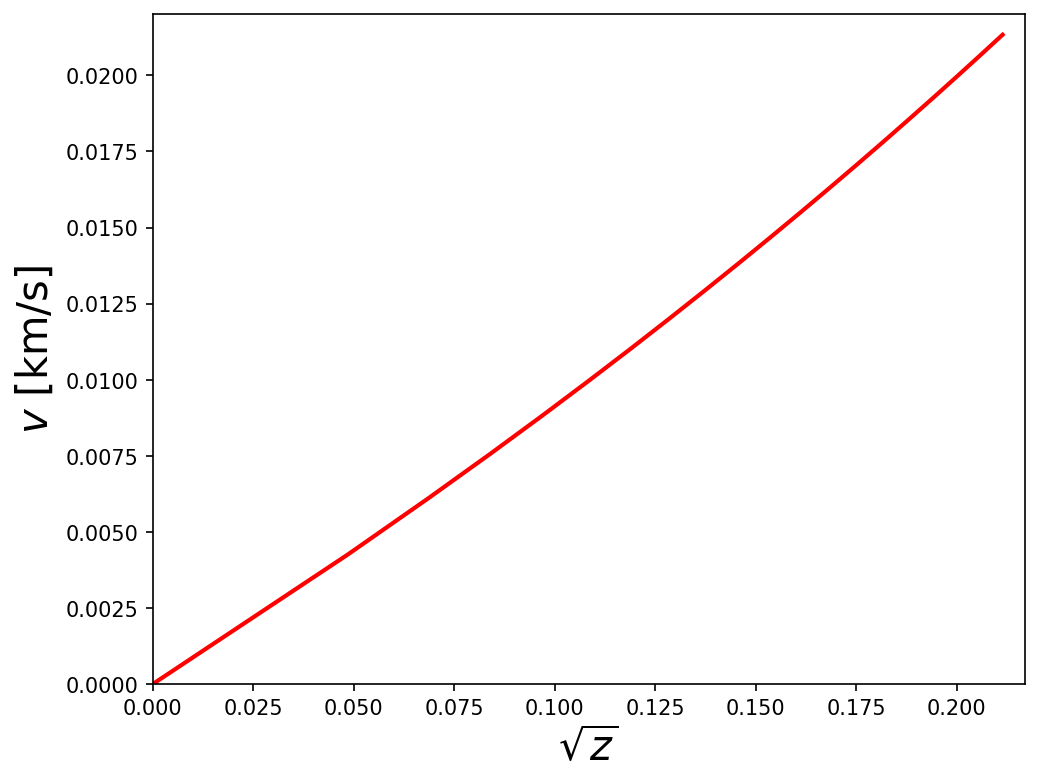

In [64]:
import numpy as np
import matplotlib.pyplot as plt
from mpl_toolkits.axes_grid1.inset_locator import inset_axes
from matplotlib.axes import Axes

vz_interp1d = interp1d(z_list, v_list, kind="linear", fill_value="extrapolate")

# --- main figure/axes ---
fig, ax = plt.subplots(figsize=(7.5, 5.8), dpi=150)

# main curve (keep your split if you need to skip a bad point around index 25)
ax.plot(np.sqrt(z_list[:20]), np.array([vz_interp1d(z) for z in z_list[:20]]), 'r', lw=2)
#ax.plot(z_list[26:], v_list[26:], 'b', lw=2)

ax.set_xlabel(r"$\sqrt{z}$", fontsize=20)
ax.set_ylabel(r"$v$ [km/s]", fontsize=20)
#ax.set_title(r"$v(z)$", fontsize=24)
ax.set_xlim(0, np.sqrt(z_list[20]))
ax.set_ylim(0, float(vz_interp1d(z_list[20])))
#ax.set_yscale("log")

plt.savefig("v_sqrt_z.pdf")
plt.show()

In [54]:
import numpy as np
from scipy.integrate import solve_ivp
import matplotlib.pyplot as plt
from RMFsolver.phase_velocity import vNtoQ_Pc

# --- 1) Define v(z) ---
'''
def vz(z):
    DelP_P_crit = P_of_r(z_crit - z)
    vel, _ = vNtoQ_Pc(T=15.0, P_crit = P_crit, DelP = DelP_P_crit - P_crit, m_s = 0, param = para.paraQMCRMF3, NM_type = "PNM", method = "numerical")
    return vel / 1e3 # in km/s
'''

# --- 2) Right-hand side dz/dt = -v(z) ---
def dzdt(t, z):
    return -vz_interp1d(z)

# --- 3) (Optional) stop when z reaches a target value ---
def hit_z_target(t, z, z_target=0.0):
    return z[0] - z_target
hit_z_target.terminal = True   # stop integration when event occurs
hit_z_target.direction = 0     # detect either direction of crossing

# --- 4) Set up and solve ---
t0, t1  = 0.0, 20.0       # time window [t0, t1]          
z0 = [0.54406]  # initial condition z(t0) = 5.0 (list or 1D array)
t_eval  = np.linspace(t0, t1, 500)  # times where you want the solution

sol = solve_ivp(
    dzdt, (t0, t1), z0,
    method="RK45",          # good default; try "Radau" if stiff
    t_eval=t_eval,
    events=lambda t, z: hit_z_target(t, z, z_target=0.0),
    rtol=1e-7, atol=1e-9
)

if not sol.success:
    raise RuntimeError(sol.message)

# --- 5) Use / plot the solution ---
t = sol.t
z = sol.y[0]

In [56]:
z[-1], zz[-1]

(np.float64(-0.026195955116432818), np.float64(0.00026031700545717213))

In [18]:
from RMFsolver.phase_velocity import vNtoQ_Pc
from RMFsolver.phase_velocity import Get_Delta_P_max

# Get the distance $z$ between phase boundary and isobar as function of time
def z_time_evolution_b(Pressure_arr, radius_arr, P_c, T, t_up=20, Interp1d_Num=10, ms=0, para = para.paraQMCRMF3, NM_ty = "PNM", meth = "numerical"):
    '''
    Get the distance $z$ between phase boundary and isobar as function of time
    ---------------------------
    Parameters:
    - Pressure_arr : an array of pressure profile
    - radius_arr   : an array of radius
    - P_c          : critical pressure for nuclear matter to quark matter phase transition
    - T            : temperature in [MeV]
    - t_up         : upper bound for time window, default = 20 [s]
    - Interp1d_Num : type = int, number of interpolation points, the larger the more precise
                     default = 10
    - ms           : strange quark mass
    - para         : relativistic mean field theory model parameter settings for nuclear matter
    - NM_ty        : nuclear matter type
                     "Beta_eq"  beta equilibriated nuclear matter
                     "PNM"      pure neutron matter
                     "SYM"      symmetrical nuclear matter
    - meth         : method, "analytical" or "numerical" (default, as robust and more accurate)

    --------------------------- 
    Returns:
    - t, z
        t: an array of time
        z: an array of z, function of t
    '''

    # 0) Safety: interpolation needs increasing x
    order = np.argsort(radius_arr)
    radius_arr = np.asarray(radius_arr, float)[order]
    Pressure_arr = np.asarray(Pressure_arr, float)[order]

    # 1) P(r) and locate z_crit from P(r)=P_c
    P_of_r = interp1d(radius_arr, Pressure_arr, kind="linear", fill_value="extrapolate")
    z_crit = float(fsolve(lambda zz: P_of_r(zz) - P_c, x0=3.0)[0])
    print("Z_crit = ", z_crit)

    # 2) initial gap z0 from Delta P_max
    DelP_max = Get_Delta_P_max(T, P_c, ms, para, NM_ty, meth)
    z_at_Pmax = float(fsolve(lambda zz: P_of_r(zz) - (P_c + DelP_max), x0=3.0)[0])
    z0 = z_crit - z_at_Pmax
    if z0 <= 0:
        raise ValueError(f"Computed z0 <= 0 (z0={z0}); check inputs/units.")
    print("z0 = ", z0)

    # 3) Pre-tabulate v(z) on [0, z0] and build cheap interpolant
    Interp1d_Num = max(int(Interp1d_Num), 2)  # need at least 2 points
    z_list = np.linspace(0.0, z0, Interp1d_Num)

    def vz_accurate(z):
        # z can be scalar or array; ensure scalar use here
        z = float(np.asarray(z).reshape(()))
        DelP_P_c = P_of_r(z_crit - z)
        vel, _ = vNtoQ_Pc(T=T, P_crit=P_c, DelP=float(DelP_P_c) - P_c,
                          m_s=ms, param=para, NM_type=NM_ty, method=meth)
        return float(vel) / 1e3  # km/s

    v_list = np.array([vz_accurate(z) for z in z_list], dtype=float)

    # Use linear (more stable with few points). Keep cubic only if you have enough points & smoothness
    vz_interp1d = interp1d(z_list, v_list, kind="linear", fill_value="extrapolate")

    # 4) ODE: dz/dt = -v(z). Must accept y as 1-D array and return 1-D array
    def dzdt(t, y):
        z = float(y[0])
        v = float(vz_interp1d(z))
        return np.array([-v], dtype=float)

    # Stop when z hits 0
    def hit_z_target(t, y, z_target=0.0):
        return y[0] - z_target

    hit_z_target.terminal = True
    hit_z_target.direction = 0

    t0, t1 = 0.0, float(t_up)
    t_eval = np.linspace(t0, t1, 500)

    # y0 must be 1-D:
    y0 = np.array([z0], dtype=float)

    try:
        sol = solve_ivp(
            dzdt, (t0, t1), y0,
            method="RK45",
            t_eval=t_eval,
            events=lambda t, y: hit_z_target(t, y, z_target=0.0),
            rtol=1e-7, atol=1e-9
        )
    except Exception as e:
        raise RuntimeError(f"solve_ivp failed with error: {e}") from e

    if not sol.success:
        raise RuntimeError(f"Integration failed: {sol.message}")

    # Return arrays directly
    t = np.array(sol.t, dtype=float)                  # shape (M,)
    z = np.array(sol.y[0], dtype=float)               # shape (M,)
    return t, z

In [19]:
from RMFsolver.phase_velocity import z_time_evolution

tt, zz = z_time_evolution_b(
    Pressure_arr = pressure, 
    radius_arr = radius,
    P_c = P_crit,
    T = 15.0, 
    Interp1d_Num = 10,
)

plt.plot(tt, zz)

Z_crit =  6.117599868035375
z0 =  1.0136903211671218


RuntimeError: solve_ivp failed with error: name 'solve_ivp' is not defined

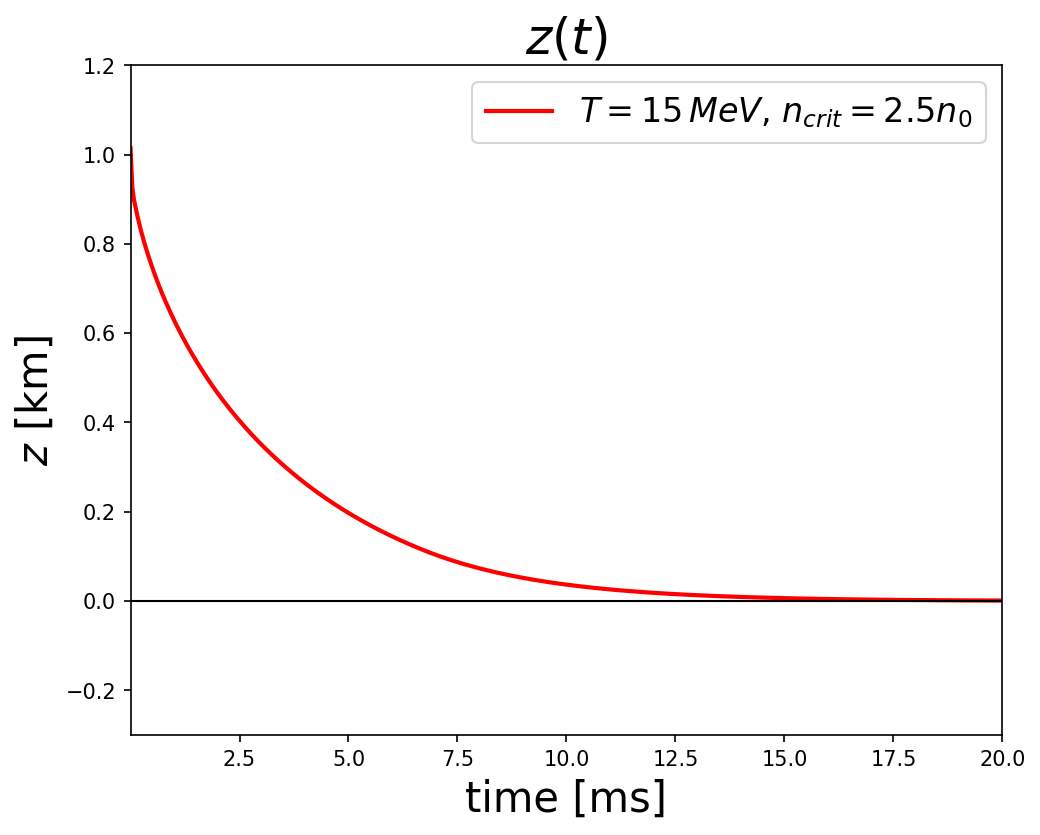

In [13]:
plt.figure(figsize=[7.5, 5.8])
plt.rcParams["figure.dpi"] = 150

plt.plot(tt, zz, lw=2, c='r', label = rf"$T=15\,MeV$, $n_{{crit}} = 2.5n_0$")
plt.plot(np.linspace(0,20,100), np.zeros(100), 'k', lw=1)
plt.xlim(5e-4, 20)
plt.ylim(-0.3, 1.2)
plt.title(rf"$z(t)$", fontsize=24)
plt.xlabel(rf"time [ms]", fontsize=20)
plt.ylabel(rf"$z$ [km]", fontsize=20)
#plt.xscale("log")
#plt.yscale("log")
#plt.xticks(np.array([1e-3, 1e-2, 1e-1, 1, 10, 20])*1e3)
plt.legend(fontsize=16)

#plt.savefig("z(t)_T15_nc2.5_logx.pdf")

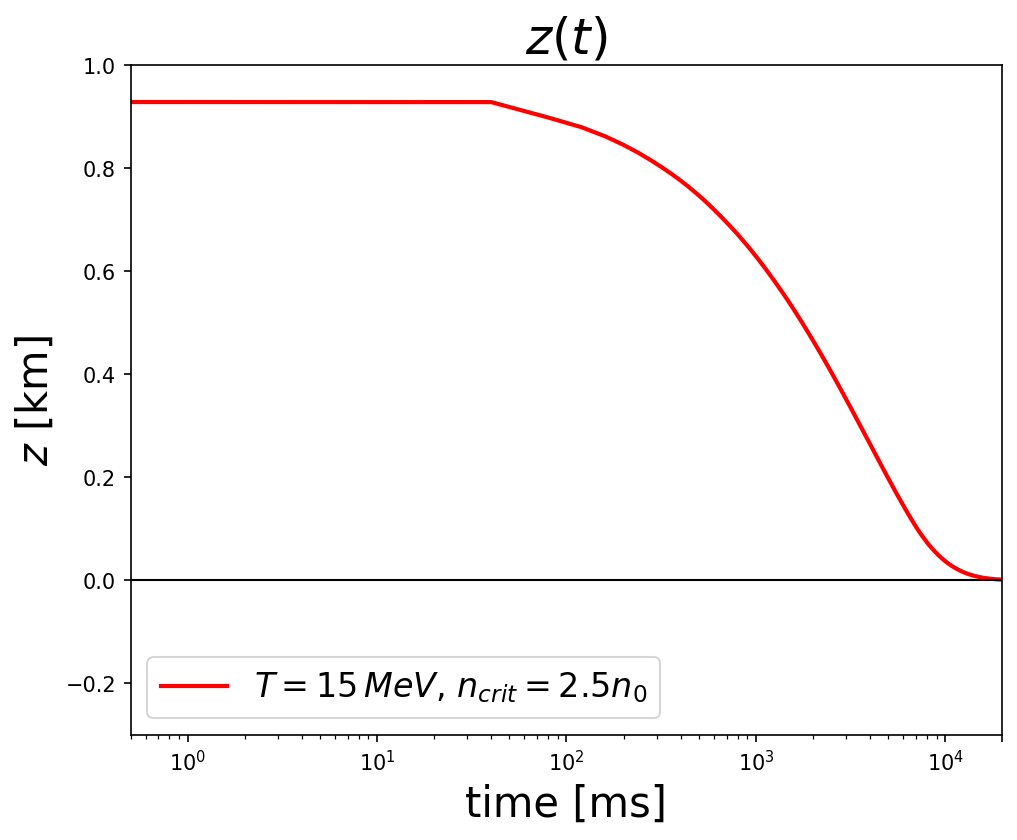

In [11]:
plt.figure(figsize=[7.5, 5.8])
plt.rcParams["figure.dpi"] = 150

plt.plot(tt*1e3, zz, lw=2, c='r', label = rf"$T=15\,MeV$, $n_{{crit}} = 2.5n_0$")
plt.plot(np.linspace(0,20,100)*1e3, np.zeros(100), 'k', lw=1)
plt.xlim(5e-4*1e3, 20*1e3)
plt.ylim(-0.3, 1)
plt.title(rf"$z(t)$", fontsize=24)
plt.xlabel(rf"time [ms]", fontsize=20)
plt.ylabel(rf"$z$ [km]", fontsize=20)
plt.xscale("log")
#plt.yscale("log")
plt.xticks(np.array([1e-3, 1e-2, 1e-1, 1, 10, 20])*1e3)
plt.legend(fontsize=16)

#plt.savefig("z(t)_T15_nc2.5_logx.pdf")

In [32]:
zz[-1]

np.float64(0.00026031700545717213)

* temperature 5MeV, 15MeV, 40MeV
* $n_crit = 2.5n_0,\; 3n_0,\; 4n_0$
* use equaly spaced contour in the 2 by 2, use same levels numbers

In [ ]:
import numpy as np
import matplotlib.pyplot as plt
import time
from scipy.integrate import quad
from scipy.interpolate import interp1d
from scipy.optimize import fsolve, approx_fprime, root_scalar, root, least_squares
from numdifftools import Gradient, Derivative
import RMFsolver.constants as const
import RMFsolver.RMFparameter as para
from RMFsolver.Solver import RMFsolve_mu, RMFpressureSYM, RMFpressurePNM, pressure_RMF
from RMFsolver.phase_velocity import P_f, n_B, vNtoQ_nc, vNtoQ_B, PQM

# Define n0 (adjust as needed)
n0 = 0.16 * const.MeV_fm**3

nc2, nc3, nc4, nc5 = 2*n0, 3*n0, 4*n0, 4.5*n0
N = 30

al = 0.6

# shaded region
Deln_cut3, T_cut3 = np.load("Shade_n_crit=3.0.npy")
Cut3 = interp1d(T_cut3, Deln_cut3, kind='linear', fill_value="extrapolate")

Deln_cut4, T_cut4 = np.load("Shade_n_crit=4.0.npy")
Cut4 = interp1d(T_cut4, Deln_cut4, kind='linear', fill_value="extrapolate")

Deln_cut4_5, T_cut4_5 = np.load("Shade_n_crit=4.5.npy")
Cut4_5 = interp1d(T_cut4_5, Deln_cut4_5, kind='linear', fill_value="extrapolate")


# create plots
fig, axs = plt.subplots(2, 2, figsize=(10, 10), sharex=True, sharey=True)
plt.subplots_adjust(wspace=0.1, hspace=0.05)


# n_crit = 2 * n0
TT = np.hstack([np.linspace(1, 20, int(N*2/5)),np.linspace(20.5, 72, int(N*3/5))])
D2 = np.linspace(0.01*n0, 0.5*n0, N)
V2 = np.load("v_n_crit=2.0.npy")
cs = axs[0,0].contour(D2/n0, TT, V2, levels=np.linspace(15, 200, 8))
axs[0,0].clabel(cs, inline=True, fontsize=7, fmt="%d")
#ax.set_title(r"$n_{crit} = $"+ncrits[idx])
axs[0,0].annotate(r"$n_{crit} = 2n_0$", xy=(0.05, 0.9), xycoords='axes fraction', fontsize=14, bbox=dict(boxstyle="round,pad=0.3", fc="white", ec="black"))


# n_crit = 3 * n0
# ----- n_crit = 3 * n0 -----
V3  = np.load("v_n_crit=3.0.npy")
t   = np.linspace(0.0, 1.0, N)
# work in ABSOLUTE density using nc3 (not n0)
Dlo  = 0.01 * n0
Dhi  = 0.5  * n0
Dmax = np.minimum(0.5 * n0, Cut3(TT) - 0.015 * n0)  
Dmax = np.maximum(Dmax, Dlo)
# grids that match V3's (i,j) layout
D_grid = Dlo + (Dmax - Dlo)[:, None] * t[None, :]            # shape (N, N)
T_grid = np.repeat(TT[:, None], N, axis=1)
Z = V3
# shaded region: Cut3(T) → 0.5 * nc3, plotted as Δn/n_crit
Dcut = Cut3(TT)                    # shape (N,)
Dhi  = 0.5 * n0 * np.ones_like(TT)
axs[0,1].fill_betweenx(
    TT, Dcut/n0, Dhi/n0, color="grey", alpha=al, zorder=0
)
levels3 = np.linspace(25, 500, 8)
cs = axs[0,1].contour(D_grid/n0, T_grid, Z, levels=levels3, zorder=1)
axs[0,1].clabel(cs, inline=True, fontsize=7, fmt="%d")
axs[0,1].set_xlim(0.01, 0.5)
axs[0,1].set_ylim(1, 72)
axs[0,1].annotate(r"$n_{crit} = 3 n_0$", xy=(0.05, 0.9),
                  xycoords='axes fraction', fontsize=14,
                  bbox=dict(boxstyle="round,pad=0.3", fc="white", ec="black"))


# n_crit = 4 * n0
# ----- n_crit = 3 * n0 -----
V4  = np.load("v_n_crit=4.0.npy")
t   = np.linspace(0.0, 1.0, N)
# work in ABSOLUTE density using nc3 (not n0)
Dlo  = 0.01 * n0
Dhi  = 0.5  * n0
Dmax = np.minimum(0.5 * n0, Cut4(TT) - 0.015 * n0)  
Dmax = np.maximum(Dmax, Dlo)
# grids that match V3's (i,j) layout
D_grid = Dlo + (Dmax - Dlo)[:, None] * t[None, :]            # shape (N, N)
T_grid = np.repeat(TT[:, None], N, axis=1)
Z = V4
# shaded region: Cut3(T) → 0.5 * nc3, plotted as Δn/n_crit
Dcut = Cut4(TT)                    # shape (N,)
Dhi  = 0.5 * n0 * np.ones_like(TT)
axs[1,0].fill_betweenx(
    TT, Dcut/n0, Dhi/n0, color="grey", alpha=al, zorder=0
)
levels4 = np.linspace(30, 500, 7)
cs = axs[1,0].contour(D_grid/n0, T_grid, Z, levels=levels4, zorder=1)
axs[1,0].clabel(cs, inline=True, fontsize=7, fmt="%d")
axs[1,0].set_xlim(0.01, 0.5)
axs[1,0].set_ylim(1, 72)
axs[1,0].annotate(r"$n_{crit} = 4 n_0$", xy=(0.05, 0.9),
                  xycoords='axes fraction', fontsize=14,
                  bbox=dict(boxstyle="round,pad=0.3", fc="white", ec="black"))


# n_crit = 4.5 * n0
V4_5  = np.load("v_n_crit=4.5.npy")
t   = np.linspace(0.0, 1.0, N)
# work in ABSOLUTE density using nc3 (not n0)
Dlo  = 0.01 * n0
Dhi  = 0.5  * n0
Dmax = np.minimum(0.5 * n0, Cut4_5(TT) - 0.015 * n0)  
Dmax = np.maximum(Dmax, Dlo)
# grids that match V3's (i,j) layout
D_grid = Dlo + (Dmax - Dlo)[:, None] * t[None, :]            # shape (N, N)
T_grid = np.repeat(TT[:, None], N, axis=1)
Z = V4_5
# shaded region: Cut3(T) → 0.5 * nc3, plotted as Δn/n_crit
Dcut = Cut4_5(TT)                    # shape (N,)
Dhi  = 0.5 * n0 * np.ones_like(TT)
axs[1,1].fill_betweenx(
    TT, Dcut/n0, Dhi/n0, color="grey", alpha=al, zorder=0
)
levels4_4 = np.linspace(50, 600, 6)
cs = axs[1,1].contour(D_grid/n0, T_grid, Z, levels=levels4_4, zorder=1)
axs[1,1].clabel(cs, inline=True, fontsize=7, fmt="%d")
axs[1,1].set_xlim(0.01, 0.5)
axs[1,1].set_ylim(1, 72)
axs[1,1].annotate(r"$n_{crit} = 4.5 n_0$", xy=(0.05, 0.9),
                  xycoords='axes fraction', fontsize=14,
                  bbox=dict(boxstyle="round,pad=0.3", fc="white", ec="black"))

axs[1, 0].set_xlabel(r"Density $\Delta n / n_0$", fontsize = 14)
axs[1, 1].set_xlabel(r"Density $\Delta n / n_0$", fontsize = 14)
axs[0, 0].set_ylabel("Temperature [MeV]", fontsize = 14)
axs[1, 0].set_ylabel("Temperature [MeV]", fontsize = 14)

plt.savefig("2by2_Grid.pdf")